# 📋 Lab 03: Evaluating Structured Outputs in 2026

## Module 03 — Valid JSON. Is it *right*? ✅

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/varoonsahgal/adv-model-eval-student/blob/main/labs/03-structured-outputs-lab.ipynb)

<center><font size="6"><b>"100% of responses are schema-valid."</b></font></center>

Then a CAD invoice gets paid in USD. <mark>Ship the next model?</mark> ⏱️ Part 1 ~30 min.

<!-- img: comic-valid-not-right.png -->
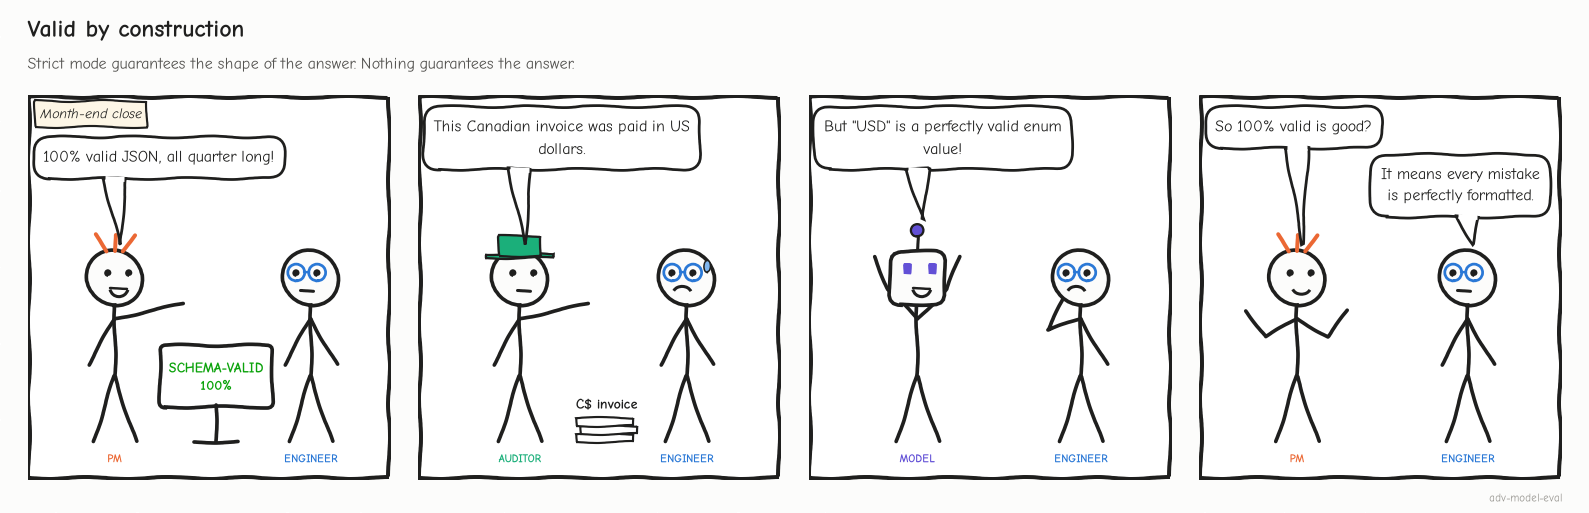

| | |
|---|---|
| ⏱️ **Time** | 45–55 min core, plus optional extensions · +30 min for the five 🏆 challenges |
| 🎚️ **Level** | Intermediate: Python dicts, JSON, a little Pydantic |
| 🔑 **Keys needed** | None. Fully offline (`PROVIDER = "mock"`); real OpenAI / Anthropic calls are an opt-in switch |
| 🧰 **Tools** | `pydantic` · `jsonschema` · `pandas` · `matplotlib` |
| ✍️ **You'll write** | Five predictions (scored at the end), impact weights (Task 4), your own audit verdicts (Task 7), business-rule validators (Task 8), your own perturbations (Task 9). Each has a safe default, so *Run All* always works |
| 🎛️ **You'll play** | 🕵️ *You're the auditor* (Task 7) and a cost-of-errors simulator (Task 10) |
| 🏁 **You'll leave with** | Field-, record- and null-level metrics, an audited answer key, and an evidence-based SHIP / BLOCK call |

**How this lab works:** ▶️ **Run** (<kbd>Shift</kbd>+<kbd>Enter</kbd>; 🧰 = just run) · ✋ **Your turn** (fill the `...`) · ❓ **Quick check** (pick, run) · 🔑 **Key takeaway**

<details><summary>🗺️ Your route: three acts, six checks</summary>

<!-- img: pipeline-2026.png -->
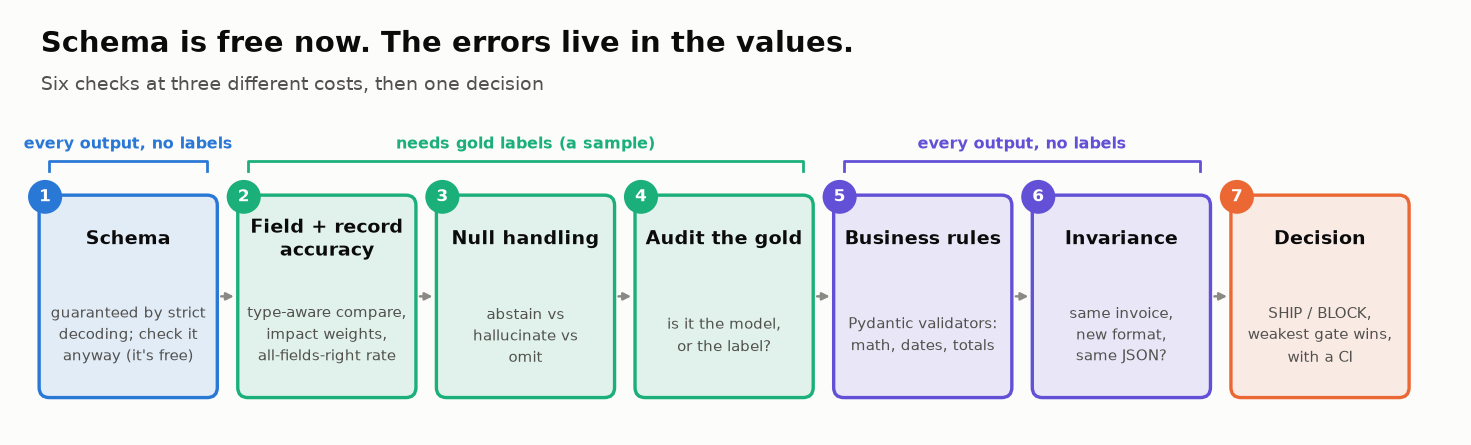

1. **Against gold** (Tasks 2–7): how often is a valid record wrong?
2. **No labels** (Tasks 8–9): what can you catch on every invoice?
3. **The decision** (Task 10): ship, and at what cost?
</details>

<details><summary>📖 Jargon decoder: 26 terms this lab uses (click to open)</summary>

| Term | Plain-English meaning | Where you'll meet it |
|---|---|---|
| **Token** | A word-piece. Models write text one token at a time | Overview, Task 2 |
| **Structured outputs / strict mode** | A provider feature that forces the response to match a schema you supply | Overview, Task 2 |
| **Constrained decoding** | How strict mode works: before each token, every choice that would break the schema is masked out | Task 2 diagram |
| **JSON Schema** | A standard JSON document declaring which keys, types and values a record may have | Task 3 |
| **Pydantic model** | A Python class that declares typed fields, validates data, and exports a JSON Schema | Tasks 2, 8 |
| **Nullable vs optional** | Nullable: the key is always there, its value may be `null`. Optional: the key may be missing. Strict mode wants every key, so absence is `null` | Tasks 2, 6 |
| **Gold labels (answer key)** | Human-written correct values for each invoice | Tasks 2, 5, 7 |
| **Comparator** | The function that decides whether a predicted value equals the gold value | Task 5 |
| **Normalisation** | Rewriting both values to one canonical form before comparing (lowercase, no punctuation, no "LLC") | Task 5 |
| **Field / record / critical-record accuracy** | Share of (invoice, field) slots right / share of invoices with every field right / every *critical* field right | Task 5 |
| **95% confidence interval (CI); Wilson interval** | The range of true rates consistent with what you measured; Wilson's formula stays honest at small n | Tasks 5, 10 |
| **OCR** | Optical character recognition: turning a scan into text. Source of `l`-for-`I` and `O`-for-`0` typos | Tasks 5, 9 |
| **Hallucination / abstention / omission** | A value invented for an empty field / a correct `null` / a printed value returned as `null` | Task 6 |
| **Payment terms** | When the bill is due. *Net 30*: 30 days after the invoice date. *Due on receipt*: immediately | Task 6 |
| **Purchase order (PO)** | The buyer's approved order, with its own number | Hook, Task 6 |
| **Three-way match** | Accounts-payable control: pay only if invoice, PO and goods receipt agree | Scenario, Task 6 |
| **Label error** | The answer key is wrong, not the model | Task 7 |
| **Locale** | A country's conventions for dates and numbers: `04/03` is 4 March in London, April 3 in Austin | Tasks 7, 9 |
| **Business rule (validator)** | A relationship every valid invoice obeys (`total = subtotal + tax`), checked in code on every output | Task 8 |
| **Vendor master** | The company's reference list of approved vendors (name, country, currency, bank details) | Task 8, Challenge 2 |
| **Invariance (metamorphic) test; perturbation** | Re-render the same invoice in another format (the perturbation); the extraction must not change | Task 9 |
| **CI (continuous integration)** | The automated tests that run on every code change. Not the confidence interval | Task 9, Stretch |
| **Release gate** | A pass/fail threshold; a release ships only if every gate passes | Task 10 |
| **Accounts payable (AP)** | The team and system that pay vendor invoices | Scenario |
| **General ledger** | The company's master record of every transaction; invoices are "posted" to it | Scenario |
| **Mock provider** | Recorded model outputs replayed offline, so everyone gets the same numbers | Setup |

</details>

<details><summary>🎯 Objectives · setup</summary>

## 🎯 Learning Objectives

Score per field and per record; measure hallucination and omission; audit the gold; write label-free rules and invariance tests; make a SHIP / BLOCK call.

## 📋 Prerequisites

Modules 01–02; Python dicts and JSON.

## ⏱️ Estimated Time

45–55 min for Tasks 1–10 across both parts.

| Tasks | Minutes |
|---|---|
| 1–3 Setup, the batch, schema validation | 10 |
| 4–5 Weights, field and record accuracy | 10 |
| 6–7 Null handling, the auditor game, gold audit | 12 |
| 8–10 Business rules, invariance, decision and its cost | 18 |

## ⚙️ Environment and Setup

Offline, no keys: `PROVIDER = "mock"` replays recorded extractions. `"openai"` / `"anthropic"` run live (numbers differ).

## 🎬 Scenario

Invoice JSON drives **payments, tax and the ledger**. Ship the new model?
</details>

---

## Task 1: Set up the environment 🔧

<big><b>A skipped cell here is a NameError twenty cells later.</b></big>

> 🎯 **Goal:** tools, the lab kit and the 20-invoice batch in memory.<br>
> ❓ **The question:** what does a "100% valid" record actually guarantee?<br>
> 👀 **Watch for:** `PROVIDER = "mock"`: everything runs offline.

▶️ **Run** the next four cells: 📦 install · ⚙️ config · 🎨 lab kit · 📦 invoice batch (collapsed; reading it spoils Task 7).

In [ ]:
%%capture
# jsonschema is the only extra; Colab already ships pydantic v2, pandas and matplotlib.
!pip install -q jsonschema "pydantic>=2"

In [ ]:
# --- Imports -------------------------------------------------------------------------------
import json
import re
from copy import deepcopy
from datetime import date, datetime, timedelta
from decimal import Decimal, ROUND_HALF_UP
from difflib import SequenceMatcher
from importlib.metadata import version
from typing import Literal, Optional

import jsonschema
import matplotlib.pyplot as plt
import pandas as pd
import pydantic
from IPython.display import Markdown, display
from pydantic import BaseModel, ConfigDict, Field, model_validator
from pydantic import ValidationError as PydanticValidationError

# --- Configuration: the ONLY place model IDs live ------------------------------------------
PROVIDER = "mock"                 # "mock" (offline, default) | "openai" | "anthropic"
OPENAI_MODEL = "gpt-6-luna"       # current low-cost OpenAI model (Nov 2026)
ANTHROPIC_MODEL = "claude-haiku-5-5"
pd.set_option("display.max_colwidth", 120)

print(f"✅ Imports OK · pydantic {pydantic.VERSION} · jsonschema {version('jsonschema')}")
print(f"🔌 PROVIDER = {PROVIDER!r} → " + ("recorded extractions, no API calls, no keys" if PROVIDER == "mock"
                                         else "LIVE calls: your numbers will differ from the Expected Output blocks"))

In [ ]:
# @title 🎨 Lab kit: insight cards, stat tiles, chart theme (run me; no need to read)
# LABKIT v2 — shared across every lab in this course. Pure Python + IPython; no installs.
# Functions you'll see used in this notebook:
#   insight(headline, body, kind="insight")   -> a callout card that states what the numbers just revealed
#   tiles([(label, value, note, status), ...])  -> a row of KPI tiles (status: good|warning|serious|critical|None)
#   verdict(decision, reasons)                  -> a SHIP / SHIP WITH CAUTION / BLOCK banner
#   style_charts()                              -> one consistent matplotlib theme (called automatically)
#   PALETTE / STATUS                            -> the colors used in every chart
#   check(label, got, expected, hint=, success=) -> grades a ✋ Your turn exercise: ✅ / ❌ + hint / ⏳ (still `...`)
#   quiz(label, choice, correct, why, wrong=)    -> grades a ❓ dropdown answer and explains it
#   todo(x)                                      -> True while an exercise blank is still `...`
#   scoreboard()                                 -> your exercise + quiz score so far, and what to revisit
import html as _html

try:
    from IPython.display import HTML as _HTML, display as _display
except ImportError:  # running as a plain script
    _HTML, _display = None, None

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
STATUS = {"good": "#0ca30c", "warning": "#fab219", "serious": "#ec835a", "critical": "#d03b3b"}
_STATUS_ICON = {"good": "✅", "warning": "⚠️", "serious": "🟠", "critical": "⛔"}

_KINDS = {
    #  kind        icon  label                    accent     tint
    "insight":    ("💡", "Insight",               "#2a78d6", "#eef5fd"),
    "surprise":   ("🤯", "Counterintuitive",      "#6250d6", "#f1effc"),
    "warning":    ("⚠️", "Watch out",             "#ec835a", "#fdf1ec"),
    "production": ("🏭", "In production",         "#1baf7a", "#ebf8f3"),
    "numbers":    ("📈", "By the numbers",        "#eda100", "#fdf6e6"),
    "research":   ("📚", "What the research says", "#52514e", "#f3f2ef"),
}


def _show(markup):
    if _display is not None:
        _display(_HTML(markup))
    else:
        import re
        print(re.sub(r"<[^>]+>", "", markup))


def _md(text):
    """Tiny formatter: **bold**, `code`, and newlines. Everything else is escaped."""
    import re
    t = _html.escape(str(text))
    t = re.sub(r"\*\*(.+?)\*\*", r"<b>\1</b>", t)
    t = re.sub(r"(?<![\w*])\*(?!\s)(.+?)(?<!\s)\*(?![\w*])", r"<i>\1</i>", t)
    t = re.sub(r"`(.+?)`", r"<code style='background:#0000000d;padding:1px 4px;border-radius:4px'>\1</code>", t)
    return t.replace("\n", "<br>")


def insight(headline, body="", kind="insight"):
    """Render a callout card. Use it right after a result to say what the result *means*."""
    icon, label, accent, tint = _KINDS.get(kind, _KINDS["insight"])
    _show(
        f"<div style='border-left:5px solid {accent};background:{tint};color:#0b0b0b;"
        f"padding:12px 16px;margin:10px 0;border-radius:8px;font-family:system-ui,-apple-system,sans-serif;"
        f"line-height:1.45;max-width:900px'>"
        f"<div style='font-size:11px;letter-spacing:.08em;text-transform:uppercase;color:#52514e;"
        f"font-weight:600'>{icon} {label}</div>"
        f"<div style='font-size:16px;font-weight:650;margin:4px 0 6px'>{_md(headline)}</div>"
        f"<div style='font-size:14px;color:#2b2b2a'>{_md(body)}</div></div>"
    )


def tiles(items):
    """items: list of (label, value, note, status). status in good|warning|serious|critical|None."""
    cells = []
    for item in items:
        label, value, note, status = (list(item) + [None, None, None, None])[:4]
        color = STATUS.get(status, "#d9d8d4")
        icon = _STATUS_ICON.get(status, "")
        cells.append(
            f"<div style='flex:1 1 160px;min-width:150px;background:#fcfcfb;border:1px solid #e4e3df;"
            f"border-top:4px solid {color};border-radius:8px;padding:10px 14px'>"
            f"<div style='font-size:12px;color:#52514e'>{_md(label)}</div>"
            f"<div style='font-size:26px;font-weight:700;color:#0b0b0b;margin:2px 0'>{_md(value)}</div>"
            f"<div style='font-size:12px;color:#52514e'>{icon} {_md(note or '')}</div></div>"
        )
    _show(
        "<div style='display:flex;flex-wrap:wrap;gap:10px;margin:10px 0;"
        "font-family:system-ui,-apple-system,sans-serif;max-width:900px'>" + "".join(cells) + "</div>"
    )


def verdict(decision, reasons=()):
    """decision: 'SHIP' | 'SHIP WITH CAUTION' | 'BLOCK' (anything else renders neutral)."""
    d = str(decision).upper()
    status = "good" if d == "SHIP" else "critical" if d.startswith("BLOCK") else "warning"
    icon = {"good": "🚀", "critical": "🛑", "warning": "⚠️"}[status]
    items = "".join(f"<li>{_md(r)}</li>" for r in reasons)
    _show(
        f"<div style='border:2px solid {STATUS[status]};border-radius:10px;padding:12px 18px;margin:10px 0;"
        f"background:#fcfcfb;color:#0b0b0b;font-family:system-ui,-apple-system,sans-serif;max-width:900px'>"
        f"<div style='font-size:22px;font-weight:800'>{icon} {_html.escape(d)}</div>"
        f"<ul style='margin:6px 0 0 18px;padding:0;font-size:14px;line-height:1.5'>{items}</ul></div>"
    )


def style_charts():
    """One chart theme for the whole course: thin marks, recessive grid, fixed color order."""
    try:
        import matplotlib as mpl
        from cycler import cycler
    except ImportError:
        return
    mpl.rcParams.update({
        "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
        "axes.edgecolor": "#b9b8b3", "axes.labelcolor": "#52514e", "axes.titlecolor": "#0b0b0b",
        "axes.titleweight": "bold", "axes.titlesize": 13, "axes.titlelocation": "left",
        "axes.spines.top": False, "axes.spines.right": False,
        "axes.grid": True, "grid.color": "#e9e8e4", "grid.linewidth": 0.8,
        "xtick.color": "#52514e", "ytick.color": "#52514e", "font.size": 11,
        "lines.linewidth": 2, "lines.markersize": 7, "legend.frameon": False,
        "axes.prop_cycle": cycler(color=PALETTE), "figure.dpi": 110,
    })


# ----------------------------------------------------------------- interactive: exercises, quizzes, score
_SCORE = {}   # label -> (kind, status) where status is "pass" | "fail" | "todo"


class _Graded(int):
    """check()/quiz() result: works like True/False (if, ==, sum) but prints nothing as a cell's last line."""
    def __repr__(self):
        return "True" if self else "False"

    def _ipython_display_(self):
        pass


def todo(x):
    """True while an exercise blank is still `...` (or None)."""
    return x is Ellipsis or x is None


def _card(icon, label, headline, body, accent, tint):
    _show(
        f"<div style='border-left:5px solid {accent};background:{tint};color:#0b0b0b;"
        f"padding:10px 16px;margin:8px 0;border-radius:8px;font-family:system-ui,-apple-system,sans-serif;"
        f"line-height:1.45;max-width:900px'>"
        f"<div style='font-size:11px;letter-spacing:.08em;text-transform:uppercase;color:#52514e;"
        f"font-weight:600'>{icon} {_md(label)}</div>"
        f"<div style='font-size:16px;font-weight:650;margin:3px 0 4px'>{_md(headline)}</div>"
        f"<div style='font-size:14px;color:#2b2b2a'>{_md(body)}</div></div>"
    )


def _same(got, expected, tol):
    try:
        import numpy as _np
        if isinstance(got, (_np.generic,)):
            got = got.item()
        if isinstance(expected, (_np.generic,)):
            expected = expected.item()
    except ImportError:
        pass
    if isinstance(expected, bool) or isinstance(got, bool):
        return got == expected
    if isinstance(expected, (int, float)) and isinstance(got, (int, float)):
        return abs(float(got) - float(expected)) <= tol * max(1.0, abs(float(expected)))
    if isinstance(expected, str) and isinstance(got, str):
        return got.strip().lower() == expected.strip().lower()
    if isinstance(expected, (set, frozenset)) or isinstance(got, (set, frozenset)):
        try:
            return set(got) == set(expected)
        except TypeError:
            return False
    return got == expected


def check(label, got, expected=None, *, ok=None, tol=1e-6, hint="", success="", reveal=False):
    """Grade a ✋ Your turn exercise.

    got:      the learner's answer (still `...` = not attempted yet: shows ⏳, never an error)
    expected: the reference answer (compared with tolerance for numbers, case-insensitively for strings)
    ok:       pass a bool instead of `expected` for custom rules (e.g. ok=my_case_fools_the_grader)
    reveal:   show the expected answer on a wrong attempt (default False: the hint teaches, the answer spoils)
    """
    if todo(got):
        _SCORE[label] = ("exercise", "todo")
        _card("⏳", f"Your turn · {label}", "Not attempted yet",
              "Replace the `...` above with your answer and re-run this cell. "
              "The lab keeps going with the reference answer, so later cells still work.", "#9a9893", "#f3f2ef")
        return _Graded(False)
    try:
        passed = bool(ok) if ok is not None else _same(got, expected, tol)
    except Exception:
        passed = False
    _SCORE[label] = ("exercise", "pass" if passed else "fail")
    if passed:
        _card("✅", f"Correct · {label}", success or "Nice. That matches the reference.", "", "#0ca30c", "#ecf8ec")
    else:
        shown = f"You got `{got!r}`" + (f"; expected `{expected!r}`" if reveal and ok is None and expected is not None else "") + "."
        _card("❌", f"Not yet · {label}", shown, (f"💡 Hint: {hint}" if hint else "Re-read the step above and try again."),
              "#d03b3b", "#fcefef")
    return _Graded(passed)


def quiz(label, choice, correct, why, wrong=None):
    """Grade a ❓ dropdown answer. choice: the @param string, e.g. "B) The average hides it".
    correct: the letter ("B"). why: the explanation (shown once answered). wrong: {letter: feedback for that pick}."""
    pick = str(choice).strip()[:1].upper()
    if not pick.isalpha():
        _SCORE[label] = ("quiz", "todo")
        _card("❓", f"Quick check · {label}", "Pick an answer in the dropdown, then run this cell.",
              "Commit before you scroll: a guess you wrote down is what makes the next result stick.", "#9a9893", "#f3f2ef")
        return _Graded(False)
    passed = pick == str(correct).strip()[:1].upper()
    _SCORE[label] = ("quiz", "pass" if passed else "fail")
    extra = (wrong or {}).get(pick, "")
    if passed:
        _card("✅", f"Quick check · {label}", f"Right: {correct}.", why, "#0ca30c", "#ecf8ec")
    else:
        _card("🔁", f"Quick check · {label}", f"Not quite: you picked {pick}, the answer is {correct}.",
              (extra + "\n" if extra else "") + why, "#ec835a", "#fdf1ec")
    return _Graded(passed)


def scoreboard():
    """Your score on every ✋ exercise and ❓ quick check you've run, plus what to revisit."""
    ex = [s for k, s in _SCORE.values() if k == "exercise"]
    qz = [s for k, s in _SCORE.values() if k == "quiz"]
    redo = [lbl for lbl, (_, s) in _SCORE.items() if s != "pass"]
    tiles([
        ("✋ Exercises solved", f"{ex.count('pass')}/{len(ex)}", f"{ex.count('todo')} not attempted",
         "good" if ex and ex.count("pass") == len(ex) else "warning"),
        ("❓ Quick checks right", f"{qz.count('pass')}/{len(qz)}", f"{qz.count('todo')} unanswered",
         "good" if qz and qz.count("pass") == len(qz) else "warning"),
    ])
    if redo:
        insight("Worth a second pass", "\n".join(f"• {r}" for r in redo), kind="warning")
    elif _SCORE:
        insight("Clean sweep", "Every exercise and quick check correct. Try the 🏆 challenges next.", kind="insight")


style_charts()
print("🎨 Lab kit loaded: insight(), tiles(), verdict(), check(), quiz(), scoreboard()")

In [ ]:
# @title 📦 Invoice batch + helpers (run me; reading the data now spoils Task 7)
# 20 synthetic invoices (fictional vendors). For each one we have:
#   SOURCES[id]       the document text the extractor saw
#   MOCK_OUTPUTS[id]  the extraction it returned, recorded from a strict structured-output run
#   GOLD[id]          the human-labelled answer key
# Plus LEGACY_OUTPUTS: two records from a 2024-style prompt-only JSON pipeline (no constrained decoding).
_NET_DAYS = {"Net 15": 15, "Net 30": 30, "Net 45": 45, "Net 60": 60}
SYMBOL = {"USD": "$", "CAD": "C$", "GBP": "£", "EUR": "€"}


def _money(x):
    return float(Decimal(str(x)).quantize(Decimal("0.01"), rounding=ROUND_HALF_UP))


def _invoice(num, vendor, address, issued, terms, items, tax_rate, currency="USD", po=None, notes=None):
    due = None
    if terms in _NET_DAYS:
        due = (date.fromisoformat(issued) + timedelta(days=_NET_DAYS[terms])).isoformat()
    lines = [{"description": d, "quantity": q, "unit_price": float(p),
              "line_total": _money(Decimal(str(q)) * Decimal(str(p)))} for d, q, p in items]
    subtotal = _money(sum(Decimal(str(li["line_total"])) for li in lines))
    tax = _money(Decimal(str(subtotal)) * Decimal(str(tax_rate)))
    return {"invoice_number": num, "vendor_name": vendor, "vendor_address": address,
            "invoice_date": issued, "due_date": due, "po_number": po, "currency": currency,
            "line_items": lines, "subtotal": subtotal, "tax_rate": tax_rate, "tax_amount": tax,
            "total_amount": _money(Decimal(str(subtotal)) + Decimal(str(tax))),
            "payment_terms": terms, "notes": notes}


def render_source(inv, date_style="iso", thousands=True, decimal_comma=False, currency_line=True,
                  vendor_upper=False, reverse_items=False):
    """Render an invoice record as the plain-text document an extractor would read."""
    sym = SYMBOL[inv["currency"]]

    def d(iso):
        x = date.fromisoformat(iso)
        return {"iso": iso, "us": x.strftime("%m/%d/%Y"), "dayfirst": x.strftime("%d/%m/%Y")}[date_style]

    def m(v):
        s = f"{v:,.2f}" if thousands else f"{v:.2f}"
        if decimal_comma:
            s = s.translate(str.maketrans({",": ".", ".": ","}))
        return sym + s

    rows = [inv["vendor_name"].upper() if vendor_upper else inv["vendor_name"], inv["vendor_address"], "",
            f"INVOICE  {inv['invoice_number']}", f"Invoice date: {d(inv['invoice_date'])}"]
    if inv["due_date"]:
        rows.append(f"Due date:     {d(inv['due_date'])}")
    if inv["po_number"]:
        rows.append(f"PO number:    {inv['po_number']}")
    rows.append(f"Terms:        {inv['payment_terms']}")
    if currency_line:
        rows.append(f"Currency:     {inv['currency']}")
    rows += ["", f"{'Description':<30}{'Qty':>5}   {'Unit price':>12}  {'Amount':>12}"]
    for li in (inv["line_items"][::-1] if reverse_items else inv["line_items"]):
        rows.append(f"{li['description']:<30}{li['quantity']:>5g} x {m(li['unit_price']):>12}  {m(li['line_total']):>12}")
    rows += ["", f"Subtotal:   {m(inv['subtotal'])}", f"Tax ({inv['tax_rate'] * 100:g}%):  {m(inv['tax_amount'])}",
             f"TOTAL:      {m(inv['total_amount'])}"]
    if inv["notes"]:
        rows.append(f"Notes: {inv['notes']}")
    return "\n".join(rows)


_BATCH = [  # (record, how the document is formatted)
    (_invoice("INV-2026-0101", "Acme Supplies Co.", "123 Main St, Springfield, IL 62704", "2026-03-02", "Net 30",
              [("Widget A", 10, 25), ("Widget B", 5, 40)], 0.08, po="PO-47120"), {}),
    (_invoice("INV-2026-0102", "TechParts Inc.", "456 Oak Ave, Austin, TX 73301", "2026-03-05", "Net 30",
              [("Circuit Board X1", 100, 12.5), ("Connector Pack", 200, 3.75), ("Solder Wire 1kg", 2, 45)], 0.0825,
              notes="Bulk order discount applied"), {}),
    (_invoice("INV-2026-0103", "Global Logistics Ltd.", "88 Harbor Rd, Long Beach, CA 90802", "2026-03-09",
              "Due on receipt", [("Freight Shipping", 1, 1500)], 0.0, notes="Expedited shipping"), {}),
    (_invoice("INV-2026-0104", "TechParts Inc.", "456 Oak Ave, Austin, TX 73301", "2026-03-12", "Net 30",
              [("USB-C Cable", 50, 6.4), ("Power Supply 12V", 20, 18.75)], 0.0825, po="PO-47188"), {}),
    (_invoice("INV-2026-0105", "Steel Works Manufacturing", "321 Industrial Pkwy, Pittsburgh, PA 15201", "2026-02-27",
              "Net 45", [("Steel Plate 4x8", 20, 185), ("Steel Rod 1in", 50, 22)], 0.06, po="PO-47002",
              notes="Delivery to loading dock B"), {}),
    (_invoice("INV-2026-0106", "Brightline Consulting Ltd", "14 Kingsway, London WC2B 6XF, UK", "2026-03-04", "Net 30",
              [("Advisory Services (days)", 3, 950)], 0.20, currency="GBP"), {"date_style": "dayfirst"}),
    (_invoice("INV-2026-0107", "Maple Leaf Print Co.", "200 King St W, Toronto, ON M5H 3T4, Canada", "2026-02-05",
              "Net 30", [("Business Cards (box)", 20, 45), ("Vinyl Banner", 2, 115)], 0.13, currency="CAD"),
     {"currency_line": False}),
    (_invoice("INV-2026-0108", "Cedar Grove Landscaping", "9 Elm Ct, Boulder, CO 80302", "2026-03-11", "Net 30",
              [("Monthly Grounds Maintenance", 1, 640)], 0.0, po="PO-47215", notes="Tax-exempt service"), {}),
    (_invoice("INV-2026-0109", "Pinnacle IT Services", "500 Tech Blvd, Raleigh, NC 27601", "2026-03-13", "Net 30",
              [("Laptop Setup", 8, 75), ("Network Audit", 1, 1200)], 0.0475, po="PO-48213"), {}),
    (_invoice("INV-2026-0110", "Quick Print Shop", "55 Paper St, Portland, OR 97201", "2026-03-16", "Net 15",
              [("Business Cards", 500, 0.1), ("Flyers (100 pack)", 3, 24)], 0.0), {}),
    (_invoice("INV-2026-0111", "CloudServ Pro", "100 Cloud Lane, Seattle, WA 98101", "2026-03-01", "Net 30",
              [("Cloud Hosting (Monthly)", 1, 899), ("SSL Certificate", 1, 49)], 0.0, po="PO-47301",
              notes="Annual renewal"), {}),
    (_invoice("INV-2026-0112", "Lakeside Medical Supply", "77 Shore Dr, Madison, WI 53703", "2026-03-17", "Net 30",
              [("Exam Gloves (case)", 25, 82), ("Hand Sanitizer 1L", 50, 21.7)], 0.055, po="PO-47333"), {}),
    (_invoice("INV-2026-0113", "Summit Office Furniture", "1200 Peak Rd, Denver, CO 80202", "2026-03-18", "Net 60",
              [("Standing Desk", 4, 489), ("Ergonomic Chair", 4, 315)], 0.0815, po="PO-47340"), {}),
    (_invoice("INV-2026-0114", "Blue Harbor Catering", "3 Pier Ave, Charleston, SC 29401", "2026-03-19",
              "Due on receipt", [("Lunch Catering (per person)", 40, 18.5)], 0.09, notes="Event: Q1 all-hands"), {}),
    (_invoice("INV-2026-0115", "Northwind Office Supply", "42 Commerce Way, Columbus, OH 43215", "2026-03-20", "Net 30",
              [("Printer Paper (case)", 10, 32.99), ("Ink Cartridge", 4, 28.5), ("Stapler", 3, 12)], 0.0575,
              po="PO-47402"), {}),
    (_invoice("INV-2026-0116", "Bayside Freight Partners LLC", "900 Dock St, Oakland, CA 94607", "2026-03-23", "Net 30",
              [("LTL Freight", 1, 780), ("Liftgate Fee", 1, 65)], 0.0), {}),
    (_invoice("INV-2026-0117", "Granite Tool & Supply", "15 Quarry Ln, Barre, VT 05641", "2026-03-24", "Net 30",
              [("Drill Bit Set", 12, 45), ("Safety Glasses", 30, 8.25)], 0.06, po="PO-47455"), {}),
    (_invoice("INV-2026-0118", "Orchard Analytics Inc.", "8 Orchard Way, Fresno, CA 93721", "2026-03-25", "Net 30",
              [("Data Pipeline Setup", 1, 1200), ("Dashboard License (seat)", 6, 85)], 0.08, po="PO-47460"), {}),
    (_invoice("INV-2026-0119", "Fernwood Janitorial", "61 Birch St, Burlington, VT 05401", "2026-03-26", "Net 45",
              [("Office Cleaning (monthly)", 1, 1150), ("Carpet Shampoo", 1, 240)], 0.06), {}),
    (_invoice("INV-2026-0120", "Atlas Security Systems", "300 Fortress Rd, Phoenix, AZ 85004", "2026-03-27", "Net 30",
              [("Camera Install", 6, 210), ("Monitoring (annual)", 1, 1800)], 0.086, po="PO-47501"), {}),
]
_TRUTH = {rec["invoice_number"]: rec for rec, _ in _BATCH}
SOURCES = {rec["invoice_number"]: render_source(rec, **style) for rec, style in _BATCH}

# The answer key, as a busy human labeller produced it.
GOLD = deepcopy(_TRUTH)
GOLD["INV-2026-0118"]["total_amount"] = 1864.80
GOLD["INV-2026-0119"]["due_date"] = None

# What the strict-mode extractor returned.
MOCK_OUTPUTS = deepcopy(_TRUTH)
_o = MOCK_OUTPUTS
_o["INV-2026-0102"].update(tax_amount=200.00, total_amount=2290.00)
_o["INV-2026-0103"]["due_date"] = "2026-04-08"
_o["INV-2026-0104"]["vendor_name"] = "TechParts lnc."
_o["INV-2026-0105"]["line_items"][1]["line_total"] = 1200.00
_o["INV-2026-0105"].update(subtotal=4900.00, tax_amount=294.00, total_amount=5194.00)
_o["INV-2026-0106"].update(invoice_date="2026-04-03", due_date="2026-03-04")
_o["INV-2026-0107"]["currency"] = "USD"
_o["INV-2026-0109"]["po_number"] = None
_o["INV-2026-0110"]["po_number"] = "PO-48213"
_o["INV-2026-0112"]["total_amount"] = 3370.43
_o["INV-2026-0115"]["line_items"] = _o["INV-2026-0115"]["line_items"][::-1]
_o["INV-2026-0116"]["vendor_name"] = "Bayside Freight Partners"
_o["INV-2026-0117"]["line_items"][0]["quantity"] = 2

# Two outputs from a 2024-style pipeline: "please answer in JSON", no constrained decoding.
LEGACY_OUTPUTS = {
    "legacy-A": {**deepcopy(_TRUTH["INV-2026-0115"]),
                 "line_items": [{"description": "Printer Paper (case)", "quantity": "10", "unit_price": "32.99",
                                 "line_total": 329.9}]},
    "legacy-B": {**deepcopy(_TRUTH["INV-2026-0110"]),
                 "line_items": "500 business cards at $0.10 each = $50.00", "currency": "US Dollars"},
}


def standin_extract(text):
    """Deterministic stand-in for the model, used ONLY for offline robustness tests (Task 9).
    It parses the document text like a model would read it, with a few realistic weaknesses."""
    def grab(pattern):
        mt = re.search(pattern, text, flags=re.M)
        return mt.group(1).strip() if mt else None

    def num(s):
        if s is None:
            return None
        s = re.sub(r"^[^\d\-]+", "", s)
        try:
            return float(s.replace(",", ""))
        except ValueError:
            return None

    def iso(s):
        if s is None or re.fullmatch(r"\d{4}-\d{2}-\d{2}", s):
            return s
        try:
            return datetime.strptime(s, "%m/%d/%Y").date().isoformat()
        except ValueError:
            return s

    lines = text.splitlines()
    currency = grab(r"^Currency:\s*(\w+)") or ("GBP" if "£" in text else "EUR" if "€" in text else "USD")
    items = [{"description": mt.group(1).strip(), "quantity": float(mt.group(2)),
              "unit_price": num(mt.group(3)), "line_total": num(mt.group(4))}
             for mt in re.finditer(r"^(\S.*?)\s{2,}(\d+(?:\.\d+)?) x\s+(\S+)\s+(\S+)$", text, flags=re.M)]
    rate = grab(r"^Tax \(([\d.]+)%\)")
    return {"invoice_number": grab(r"^INVOICE\s+(\S+)"), "vendor_name": lines[0].strip(),
            "vendor_address": lines[1].strip(), "invoice_date": iso(grab(r"^Invoice date:\s*(\S+)")),
            "due_date": iso(grab(r"^Due date:\s*(\S+)")), "po_number": grab(r"^PO number:\s*(\S+)"),
            "currency": currency, "line_items": items, "subtotal": num(grab(r"^Subtotal:\s*(\S+)")),
            "tax_rate": round(float(rate) / 100, 6) if rate else None,
            "tax_amount": num(grab(r"^Tax \([^)]*\):\s*(\S+)")), "total_amount": num(grab(r"^TOTAL:\s*(\S+)")),
            "payment_terms": grab(r"^Terms:\s*(.+)$"), "notes": grab(r"^Notes:\s*(.+)$")}


def wilson(k, n, z=1.96):
    """95% Wilson score interval for a proportion k/n (well-behaved for small n and rates near 0 or 1)."""
    if n == 0:
        return (0.0, 1.0)
    p = k / n
    den = 1 + z * z / n
    centre = (p + z * z / (2 * n)) / den
    half = z * ((p * (1 - p) / n + z * z / (4 * n * n)) ** 0.5) / den
    return (max(0.0, centre - half), min(1.0, centre + half))


print(f"📦 Loaded {len(SOURCES)} invoices: source documents, recorded extractions, gold labels "
      f"(+{len(LEGACY_OUTPUTS)} legacy outputs)")

✋ **Your turn (warm-up):** run the collapsed answer key, then fill the blank below it. Every exercise works this way.

In [ ]:
# @title 🧰 Reference answer for the exercise below (hidden · spoiler)
_ref_tax = _money(2090.00 * 0.0825)

In [ ]:
# ✋ Your turn (warm-up): INV-2026-0102 prints a subtotal of $2,090.00 taxed at 8.25%.
#    The strict-mode extraction says tax_amount = 200.00. What should it say?
subtotal, tax_rate = 2090.00, 0.0825

my_tax = ...   # ✏️ one expression using subtotal and tax_rate

check("Warm-up: INV-2026-0102's tax", my_tax, _ref_tax, tol=1e-4,
      hint="Tax is the subtotal times the rate, with the rate as a fraction (8.25% = 0.0825).",
      success=f"${_ref_tax:,.2f}. The record's $200.00 is ${200 - _ref_tax:.2f} too much: the hook's tax line, in a record that passes every schema check.")

<details><summary>📋 <b>Checkpoint</b>: compare with the expected output</summary>

**Checkpoint ✅** Four lines: `✅ Imports OK…` through `📦 Loaded 20 invoices…`.
</details>

In [ ]:
# @title ❓ Quick check: the dashboard reads 100% schema-valid. What does that guarantee?
answer = "— pick one —"  # @param ["— pick one —", "A) Every value matches the document", "B) Every record has the right keys, types and allowed values", "C) No arithmetic errors: the totals add up", "D) The model read the right invoice"]
quiz('What 100% valid guarantees', answer, correct="B",
     why="Strict mode masks every token the schema forbids, so the shape is guaranteed. USD and CAD are both allowed values, and a wrong total is still a number.",
     wrong={"A": 'That is value-correctness. Nothing guarantees it; this lab measures it.',
          "C": 'The grammar enforces types, not total = subtotal + tax (Task 8).',
          "D": 'A valid record can hold a value copied from another document (Task 6).'})

<table><tr><td>

🔑 **Key takeaway**<br>
<font size="5" color="#2a78d6"><b>Schema-valid means well-formed, not right.</b></font>

</td></tr></table>

---

🧭 **Where you are:** Act 1 of 3 (Tasks 2–7): measure the batch against gold, then audit the gold.

## Task 2: Meet the batch, and how it was produced 📄

<big><b>This is the extractor your accounts-payable team would deploy tomorrow.</b></big>

> 🎯 **Goal:** read the schema behind every record, then one record beside its source.<br>
> ❓ **The question:** if the schema allows both `USD` and `CAD`, what stops the wrong one?<br>
> 👀 **Watch for:** `tax_amount`: the page and the record disagree.

<!-- img: constrained-decoding.png -->
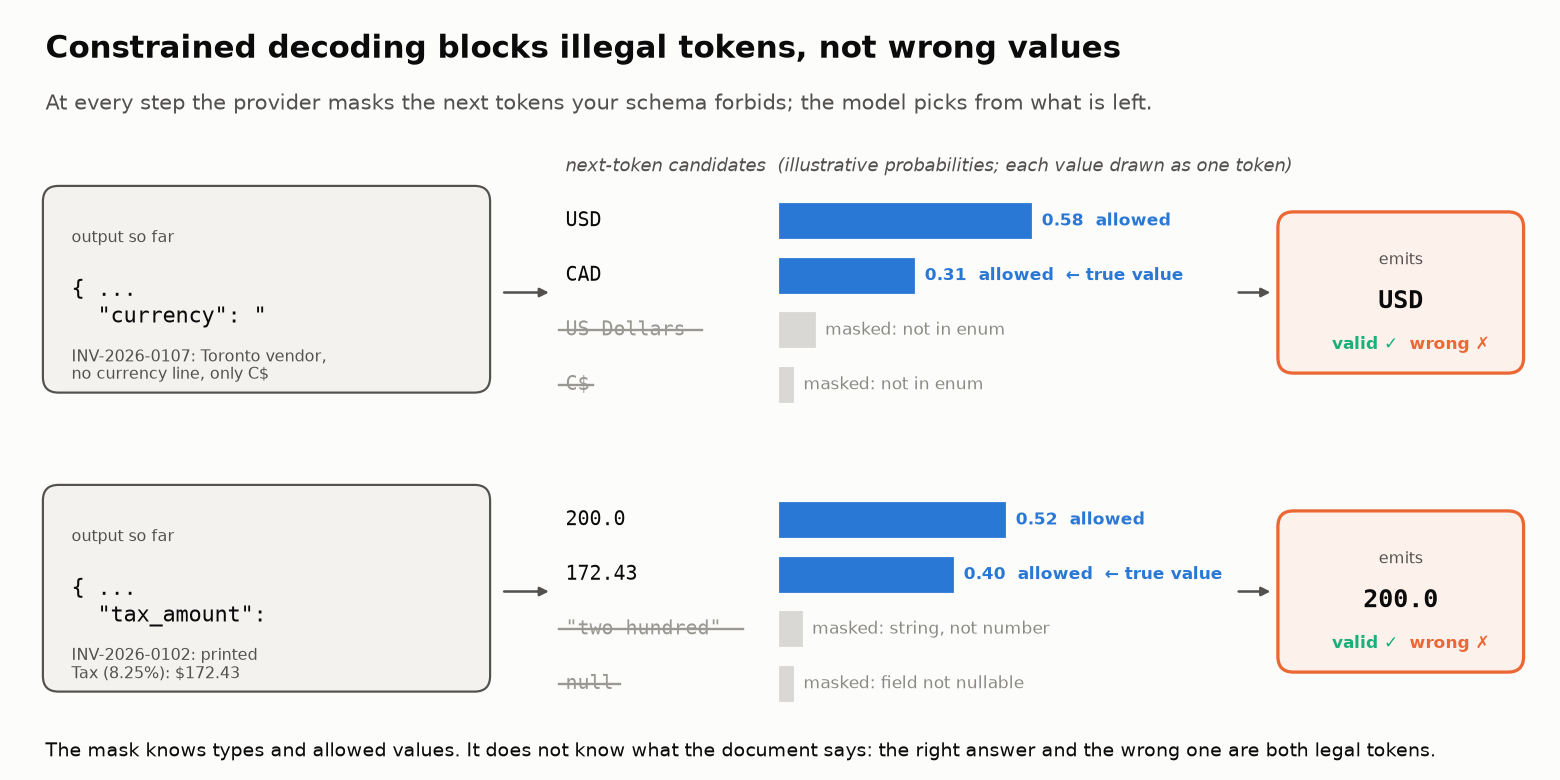

<sub>🖼️ *The mask enforces types and allowed values. `USD` and `CAD` are both legal, so the grammar cannot stop the wrong one.*</sub>

> 📘 **Concept · Constrained decoding (strict structured outputs)**
>
> **What it is:** at every token the API masks what the schema forbids, so the output is valid JSON of the right shape by construction.
>
> **What it can't tell you:** which of the allowed values is true. `USD` and `CAD` are both legal at the currency key; `200.00` is a perfectly legal wrong tax.
>
> **Anchor:** INV-2026-0102 is 100% schema-valid and pays the wrong amount.

▶️ **Run:** the `Invoice` model *is* the schema. 👀 **Key order is generation order:** the items come before the sums.

In [ ]:
class LineItem(BaseModel):
    model_config = ConfigDict(extra="forbid")
    description: str
    quantity: float
    unit_price: float
    line_total: float


class Invoice(BaseModel):
    """The extraction schema. Field descriptions are sent to the model as instructions."""
    model_config = ConfigDict(extra="forbid")
    invoice_number: str
    vendor_name: str = Field(description="Legal name exactly as printed")
    vendor_address: str
    invoice_date: str = Field(description="Issue date as YYYY-MM-DD")
    due_date: Optional[str] = Field(description="YYYY-MM-DD, or null if no due date is printed")
    po_number: Optional[str] = Field(description="Purchase-order number, or null if none is printed")
    currency: Literal["USD", "CAD", "GBP", "EUR"]
    line_items: list[LineItem]
    subtotal: float
    tax_rate: float = Field(description="Fraction, e.g. 0.0825 for 8.25%")
    tax_amount: float
    total_amount: float
    payment_terms: str
    notes: Optional[str] = Field(description="Free-text note printed on the invoice, or null")


EXTRACTION_INSTRUCTIONS = (
    "Extract this invoice into the schema. Copy values exactly as printed. "
    "If a field is not printed on the invoice, return null. Never infer, compute or guess a value."
)

▶️ **Run** (code hidden, nothing to read): the live API path, idle while `PROVIDER = "mock"`.

In [ ]:
# @title 🔌 Live extraction with OpenAI / Anthropic structured outputs (hidden · 30 lines · used only when PROVIDER != 'mock')
def extract_invoice(source_text: str) -> dict:
    """Live extraction with native structured outputs. Not called while PROVIDER == 'mock'."""
    if PROVIDER == "openai":
        from openai import OpenAI
        resp = OpenAI().responses.parse(          # Responses API (recommended for new projects)
            model=OPENAI_MODEL,
            instructions=EXTRACTION_INSTRUCTIONS,
            input=source_text,
            text_format=Invoice,                  # strict structured output: constrained decoding
        )
        if resp.output_parsed is None:            # refusal or incomplete response
            raise RuntimeError("No parsed output (refusal or incomplete response)")
        return resp.output_parsed.model_dump()
    if PROVIDER == "anthropic":
        import anthropic
        resp = anthropic.Anthropic().messages.parse(
            model=ANTHROPIC_MODEL,
            max_tokens=4096,
            system=EXTRACTION_INSTRUCTIONS,
            messages=[{"role": "user", "content": source_text}],
            output_format=Invoice,                # structured outputs; no temperature (HTTP 400 since API 2026-10-21)
        )
        if resp.stop_reason != "end_turn":        # "refusal" or "max_tokens" means no trustworthy record
            raise RuntimeError(f"Extraction stopped early: stop_reason={resp.stop_reason!r}")
        return resp.parsed_output.model_dump()
    raise ValueError(f"Unknown PROVIDER {PROVIDER!r}")

▶️ **Run:** loads the 20 extractions, prints INV-2026-0102 → compare `Tax` on the page with `tax_amount`.

In [ ]:
# 👀 Look at: in mock mode the batch is 20 recorded strict-mode extractions; the schema above is what produced them.
# --- Build the batch -------------------------------------------------------------------------
if PROVIDER == "mock":
    outputs = deepcopy(MOCK_OUTPUTS)              # recorded strict-mode responses
else:
    outputs = {iid: extract_invoice(text) for iid, text in SOURCES.items()}

FIELDS = list(Invoice.model_fields)
example_id = "INV-2026-0102"
print(f"📄 SOURCE DOCUMENT  {example_id}\n" + "─" * 66)
print(SOURCES[example_id])
print("\n🤖 EXTRACTION (abridged)\n" + "─" * 66)
shown = {k: v for k, v in outputs[example_id].items() if k not in ("line_items", "vendor_address")}
print(json.dumps(shown, indent=1))

tiles([
    ("Invoices in the batch", len(outputs), "one extraction each", None),
    ("Fields per invoice", len(FIELDS), "incl. a nested line_items list", None),
    ("Gold labels", len(GOLD), "human answer key", None),
    ("Provider", PROVIDER, "offline replay" if PROVIDER == "mock" else "live API", None),
])

▶️ **Run** (code hidden): 📚 does a strict schema cost accuracy?

In [ ]:
# @title 🧰 Card: does a strict schema cost accuracy? (hidden · 12 lines)
insight(
    "Reason free, constrain late: whether constraints cost accuracy is still open",
    "Tam et al. (*Let Me Speak Freely?*, EMNLP 2024) found format restrictions degraded reasoning; the *Say What You "
    "Mean* rebuttal (2024) blamed prompt and parsing artifacts. 2026 work finds a real but conditional cost: *The "
    "Constraint Tax* (arXiv 2605.26128) measures accuracy loss under strict schemas, worst for small models, and "
    "arXiv 2604.03616 sees reasoning degrade in open-weight models. *Thinking Before Constraining* (arXiv 2601.07525) "
    "reports gains of up to 27% from letting the model reason unconstrained (or in a leading `reasoning` field) "
    "before it emits the constrained record.\n"
    "**Rule of thumb:** copy-the-value extraction like this one: constrain directly. Anything needing arithmetic or "
    "judgement: reason first, constrain last, and measure both on your own eval set.",
    kind="research",
)

✋ **Your turn:** which fields can say "not printed"?

In [ ]:
# @title 🧰 Reference answer for the exercise below (hidden · spoiler)
_ref_nullable = {f for f, info in Invoice.model_fields.items() if type(None) in getattr(info.annotation, "__args__", ())}

In [ ]:
# ✋ Your turn: a field can say "not printed" only if null is a legal value for it.
#    Read the Invoice class above: which fields allow null?
my_nullable = ...   # ✏️ a set of field names, e.g. {"vendor_name", "subtotal"}

check("Fields that can say 'not printed'", my_nullable, _ref_nullable,
      hint="Look for Optional[...] in the annotations. In strict mode Optional means nullable: the key stays, the value may be None.",
      success=f"{', '.join(sorted(_ref_nullable))}: {len(_ref_nullable)} of {len(FIELDS)}. The other {len(FIELDS) - len(_ref_nullable)} must hold *some* value even when the page prints none. Task 6 measures what the model does with that.")

<details><summary>📋 <b>Checkpoint</b>: compare with the expected output</summary>

**Checkpoint ✅** The page says `Tax (8.25%): $172.43`; the record says `"tax_amount": 200.0`. Tiles **20** · **14** · **20** · **mock**.
</details>

In [ ]:
# @title ❓ Quick check: why does line_items come before subtotal and total_amount in the schema?
answer = "— pick one —"  # @param ["— pick one —", "A) Pydantic sorts fields alphabetically", "B) JSON Schema requires arrays first", "C) It makes the JSON easier for people to read", "D) Strict outputs follow key order, so the items are written before the sums that depend on them"]
quiz('Why key order matters', answer, correct="D",
     why="OpenAI documents that strict outputs follow the schema's key order. Put the evidence (items) before the conclusions (subtotal, total).",
     wrong={"A": "The class isn't alphabetical (vendor_name comes before invoice_date); Pydantic keeps declaration order.",
          "B": "JSON Schema doesn't constrain property order at all.",
          "C": 'People read the page, not the JSON; the order is for the model.'})

<table><tr><td>

🔑 **Key takeaway**<br>
<font size="5" color="#2a78d6"><b>Constrained decoding guarantees a legal value at every key, not the true one.</b></font>

</td></tr></table>

---

## Task 3: Schema validation: still necessary, no longer informative 📐

<big><b>Reporting schema validity as quality is how a wrong tax amount ships under a green dashboard.</b></big>

> 🎯 **Goal:** validate 20 strict and 2 legacy prompt-only outputs against a **JSON Schema**.<br>
> ❓ **The question:** once validity reads 100%, what is it still good for?<br>
> 👀 **Watch for:** INV-2026-0102 and its wrong tax, inside the 100%.

▶️ **Run:** the JSON Schema mirrors `Invoice`: nullable = `["string", "null"]`, every key `required`.

In [ ]:
DATE = r"^\d{4}-\d{2}-\d{2}$"
invoice_schema = {
    "type": "object",
    "additionalProperties": False,
    "required": FIELDS,                                   # strict modes require every key (nullable ≠ optional)
    "properties": {
        "invoice_number": {"type": "string", "pattern": r"^INV-\d{4}-\d{4}$"},
        "vendor_name": {"type": "string", "minLength": 1},
        "vendor_address": {"type": "string"},
        "invoice_date": {"type": "string", "pattern": DATE},
        "due_date": {"type": ["string", "null"], "pattern": DATE},
        "po_number": {"type": ["string", "null"]},
        "currency": {"type": "string", "enum": ["USD", "CAD", "GBP", "EUR"]},
        "line_items": {
            "type": "array", "minItems": 1,
            "items": {"type": "object", "additionalProperties": False,
                      "required": ["description", "quantity", "unit_price", "line_total"],
                      "properties": {"description": {"type": "string"},
                                     "quantity": {"type": "number", "minimum": 0},
                                     "unit_price": {"type": "number", "minimum": 0},
                                     "line_total": {"type": "number", "minimum": 0}}}},
        "subtotal": {"type": "number", "minimum": 0},
        "tax_rate": {"type": "number", "minimum": 0, "maximum": 1},
        "tax_amount": {"type": "number", "minimum": 0},
        "total_amount": {"type": "number", "minimum": 0},
        "payment_terms": {"type": "string"},
        "notes": {"type": ["string", "null"]},
    },
}

▶️ **Run:** `iter_errors()` collects **all** errors, not just the first.

In [ ]:
validator = jsonschema.Draft202012Validator(invoice_schema)


def schema_errors(record):
    """All schema violations for one record, as readable strings (empty list = valid)."""
    return [f"{'.'.join(map(str, e.absolute_path)) or '(root)'}: {e.message}" for e in validator.iter_errors(record)]


def pydantic_ok(record):
    try:
        Invoice.model_validate(record)
        return True
    except PydanticValidationError:
        return False

▶️ **Run:** validates the strict batch and 2024-style legacy outputs (no constrained decoding) → read the legacy errors.

In [ ]:
# 👀 Look at: the legacy records fail on TYPES; the strict batch passes with a wrong tax inside it.
schema_results = {iid: schema_errors(rec) for iid, rec in outputs.items()}
n_valid = sum(not errs for errs in schema_results.values())
n_pyd = sum(pydantic_ok(rec) for rec in outputs.values())
legacy_results = {lid: schema_errors(rec) for lid, rec in LEGACY_OUTPUTS.items()}
n_legacy_valid = sum(not errs for errs in legacy_results.values())

print(f"Strict batch: {n_valid}/{len(outputs)} schema-valid · {n_pyd}/{len(outputs)} parse into Invoice")
for lid, errs in legacy_results.items():
    print(f"\n{lid}: {'✅ valid' if not errs else f'❌ {len(errs)} error(s)'}")
    for e in errs:
        print(f"   → {e[:90]}")

schema_rate = n_valid / len(outputs)
tiles([
    ("Strict batch: schema-valid", f"{schema_rate:.0%}", f"{n_valid}/{len(outputs)} records", "good" if schema_rate == 1 else "critical"),
    ("Strict batch: Pydantic parse", f"{n_pyd}/{len(outputs)}", "Invoice.model_validate", "good" if n_pyd == len(outputs) else "critical"),
    ("Legacy prompt-only JSON", f"{n_legacy_valid}/{len(LEGACY_OUTPUTS)}", "no constrained decoding", "critical" if n_legacy_valid < len(LEGACY_OUTPUTS) else "good"),
])

▶️ **Run** (code hidden): two cards on what 100% means.

In [ ]:
# @title 🧰 Cards: what 100% schema-valid means (hidden · 18 lines)
insight(
    f"{schema_rate:.0%} schema-valid, and that number cannot tell a good invoice from a bad one",
    f"All {n_valid} strict-mode records pass, including INV-2026-0102 with its wrong tax. Validity is true *by "
    "construction*, so as a quality metric it carries no information. The legacy pipeline shows what the check is "
    f"still for: {len(LEGACY_OUTPUTS) - n_legacy_valid} of {len(LEGACY_OUTPUTS)} prompt-only outputs are malformed "
    "(numbers as strings, a sentence instead of a list, an invalid currency code).\n"
    "**Rule of thumb:** keep schema validation as a free pipeline-health gate that must read 100%; anything less is "
    "a bug or a provider change, not a quality signal.",
)
insight(
    "Valid JSON stopped being the hard part: the benchmarks agree",
    "\"% valid JSON\" is an outdated headline metric for API models with strict mode, but not everywhere: in "
    "**ExtractBench** (arXiv 2602.12247, 2026) only **51%** of 210 frontier-model PDF-to-JSON attempts were valid "
    "JSON at all, because complex schemas and models without grammar-constrained decoding still break. For this "
    "lab: keep the check as pipeline health, and remember the grammar enforces *types*, not sums or date order "
    "(Task 8).",
    kind="research",
)

🔍 **What just happened:** INV-2026-0102 is inside the 100%; the legacy records fail on **types**.

✋ **Your turn:** fix legacy-A's types, then see what validity bought.

In [ ]:
# @title 🧰 Reference answer for the exercise below (hidden · spoiler)
def _valid_after_fix(q, p):
    rec = deepcopy(LEGACY_OUTPUTS["legacy-A"])
    rec["line_items"][0].update(quantity=q, unit_price=p)
    return not schema_errors(rec)

In [ ]:
# ✋ Your turn: legacy-A failed only because two numbers arrived as strings ("10" and "32.99").
#    Make it schema-valid.
my_quantity = ...     # ✏️ the quantity, as a number
my_unit_price = ...   # ✏️ the unit price, as a number

fixed = deepcopy(LEGACY_OUTPUTS["legacy-A"])
fixed["line_items"][0].update(quantity=my_quantity, unit_price=my_unit_price)
lines_sum = sum(li["line_total"] for li in fixed["line_items"])
blank = todo(my_quantity) or todo(my_unit_price)
check("Make legacy-A schema-valid", ... if blank else schema_errors(fixed),
      ok=not blank and _valid_after_fix(my_quantity, my_unit_price),
      hint="The schema wants type number: write the values without quotes.",
      success=f"Valid now, and still wrong: {len(fixed['line_items'])} line item where the invoice prints {len(GOLD['INV-2026-0115']['line_items'])}, "
              f"and a ${fixed['subtotal']:,.2f} subtotal over lines summing to ${lines_sum:,.2f}. The schema checks types, not truth.")

<details><summary>📋 <b>Checkpoint</b>: compare with the expected output</summary>

**Checkpoint ✅** `Strict batch: 20/20 schema-valid · 20/20 parse into Invoice`; legacy-A and legacy-B **❌ 2 error(s)** each. Tiles **100%** · **20/20** · **0/2**.
</details>

🗣️ **Say it to a colleague:** "Schema validity is a pipeline-health gate that must read 100%. The moment it does, it stops being a quality metric."

In [ ]:
# @title ❓ Quick check: next week schema validity reads 99%. What happened?
answer = "— pick one —"  # @param ["— pick one —", "A) A pipeline bug or provider change: strict mode should never miss", "B) The model got 1% worse at extraction", "C) Normal noise: 99% is fine", "D) Some invoices were harder to read"]
quiz('Validity drops to 99%', answer, correct="A",
     why="Validity is guaranteed by construction, so any drop means something broke: a schema change, a fallback to prompt-only JSON, a provider update. It is never a quality signal.",
     wrong={"B": 'Quality lives in the values; validity never measured it.',
          "C": 'A guaranteed property has no noise. 99% means something broke.',
          "D": 'A hard invoice gets a wrong value, not an invalid one.'})

<table><tr><td>

🔑 **Key takeaway**<br>
<font size="5" color="#2a78d6"><b>Gate on schema validity at 100%; never report it as quality.</b></font>

</td></tr></table>

---

## Task 4: 🧠 Your Turn: decide what "wrong" costs ⚖️

<big><b>Equal weights pay the wrong vendor as calmly as they misspell a note.</b></big>

> 🎯 **Goal:** a business-impact weight per field, and the **critical** fields: one error makes the record unusable.<br>
> ❓ **The question:** can a high weighted average still pay the wrong amount?<br>
> 👀 **Watch for:** `total_amount` next to `notes`.

▶️ **Run:** the reference weights; weight ≥ 0.8 makes a field **critical**.

In [ ]:
# The reference weights. Ask of every field: "if THIS is wrong, what happens next?"
field_weights = {
    "invoice_number": 1.0,   # reconciliation key
    "vendor_name": 0.9,      # who gets paid
    "vendor_address": 0.3,   # correspondence
    "invoice_date": 0.8,     # accounting and tax period
    "due_date": 0.6,         # late fees, cash planning
    "po_number": 0.6,        # three-way match with purchasing
    "currency": 1.0,         # same digits, different money
    "line_items": 0.8,       # what was bought: expense coding, audit
    "subtotal": 0.8,         # pre-tax amount
    "tax_rate": 0.7,         # must match the jurisdiction
    "tax_amount": 0.9,       # flows into tax reporting
    "total_amount": 1.0,     # THE number that gets paid
    "payment_terms": 0.4,
    "notes": 0.1,
}
CRITICAL_MIN_WEIGHT = 0.8   # 👀 Look at: one wrong field at or above this weight fails the whole record


CRITICAL = [f for f in FIELDS if field_weights[f] >= CRITICAL_MIN_WEIGHT]
for f, w in sorted(field_weights.items(), key=lambda kv: -kv[1]):
    print(f"  {f:15s} {w:.1f} {'█' * int(w * 20):20s} {'◀ critical' if f in CRITICAL else ''}")

crit_share = sum(field_weights[f] for f in CRITICAL) / sum(field_weights.values())
insight(
    f"{len(CRITICAL)} of {len(FIELDS)} fields are critical, and they carry {crit_share:.0%} of the weight",
    f"Critical: {', '.join(f'`{f}`' for f in CRITICAL)}. From here on a record counts as usable only if **every** "
    "critical field is right: that is the gate, and no weight can replace it.\n"
    "**Rule of thumb:** weight for the dashboard, gate on critical fields, and get the weights from the people who "
    "absorb the errors (finance, tax, support), not from the engineer writing the scorer.",
    kind="numbers",
)

✋ **Your turn:** weight one record the way a dashboard would.

In [ ]:
# @title 🧰 Reference answer for the exercise below (hidden · spoiler)
_ref_weighted = (1.0 + 0.9 + 1.0 + 0.4 + 0.1) / (1.0 + 0.9 + 1.0 + 1.0 + 0.4 + 0.1)   # 3.4 / 4.4

In [ ]:
# ✋ Your turn: one extracted invoice, six of its fields, the reference weights. Only total_amount is wrong.
six_weight = {"invoice_number": 1.0, "vendor_name": 0.9, "currency": 1.0, "total_amount": 1.0, "payment_terms": 0.4, "notes": 0.1}
six_right = {"invoice_number": 1, "vendor_name": 1, "currency": 1, "total_amount": 0, "payment_terms": 1, "notes": 1}

my_weighted = ...   # ✏️ weighted accuracy = Σ (right × weight) ÷ Σ weight

check("Weighted accuracy of one record", my_weighted, _ref_weighted, tol=1e-3,
      hint="Multiply each field's 1 or 0 by its weight, add those up, and divide by the sum of all six weights.",
      success=f"{_ref_weighted:.0%}, against a raw average of {5 / 6:.0%}. Weighting made the wrong total cost more, yet both averages look passable, and this record pays the wrong amount.")

<!-- img: weighted-scoring.png -->
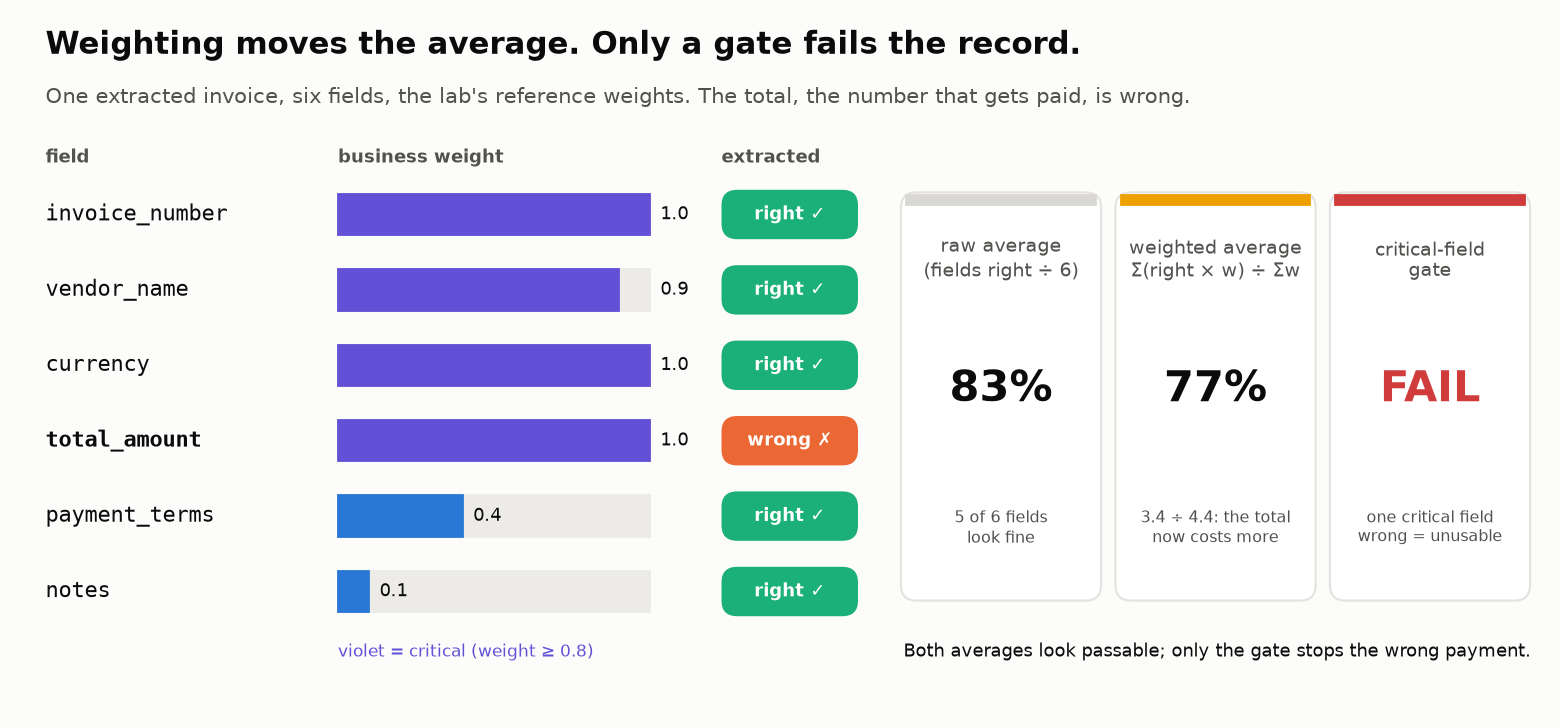

<sub>🖼️ *Weighting moves the average (83% → 77%); only the gate fails the record.*</sub>

🔍 **What just happened:** **weighting** changes how much a wrong field lowers the average. **Gating** fails the record when any critical field is wrong. <mark>No weight can do a gate's job.</mark>

<details><summary>📋 <b>Checkpoint</b>: compare with the expected output</summary>

**Checkpoint ✅** Card: **8 of 14 fields are critical, and they carry 73% of the weight**.
</details>

In [ ]:
# @title ❓ Quick check: 13 of 14 fields are right; the wrong one is total_amount. Weighted accuracy is 90%. Is the record usable?
answer = "— pick one —"  # @param ["— pick one —", "A) Yes: 90% clears a 90% bar", "B) Yes, if total_amount weighs less than 1.0", "C) No: one wrong critical field makes it unusable, whatever the average", "D) Only a human can tell"]
quiz('Usable at 90% weighted?', answer, correct="C",
     why="It pays the wrong amount. Weighted accuracy is for the dashboard; the release decision gates on critical-record accuracy (Task 5).",
     wrong={"A": "An average can't fail a record: 13 right fields offset the one that pays.",
          "B": 'Any critical field (weight ≥ 0.8) fails the gate.',
          "D": 'The gate is mechanical: a critical field is wrong, so the record is.'})

<table><tr><td>

🔑 **Key takeaway**<br>
<font size="5" color="#2a78d6"><b>Weight for the dashboard; gate on critical fields.</b></font>

</td></tr></table>

✍️ **Your call** (double-click to edit): which weight would you want a finance or tax partner to review? *Your answer…*

---

## Task 5: Field accuracy *and* record accuracy: the plot twist 🎯

<big><b>Field accuracy is what the model does; record accuracy is what the customer gets.</b></big>

> 🎯 **Goal:** score all 280 (invoice, field) slots against gold, then report the batch per field and per record.<br>
> ❓ **The question:** the batch is 100% valid. How many invoices are fully right?<br>
> 👀 **Watch for:** the gap between the per-field and the per-invoice numbers.

**Record accuracy** counts invoices with *every* field right; **critical-record accuracy**, every *critical* field.

<details><summary>⚖️ The comparators (a plain <code>==</code> fails two correct records)</summary>

| Field | Equal when |
|---|---|
| Money | to the cent |
| `vendor_name` | after casefold, no punctuation, no Inc / LLC / Ltd |
| `line_items` | same items, any order |
| One side `null` | never |
</details>

In [ ]:
# @title 🔮 Predict: all 20 records are schema-valid. What share are fully correct (every field right)?
fully_correct_will_be = "— pick one —"  # @param ["— pick one —", "A) 90% or more", "B) about 75%", "C) about 60%", "D) under half"]
print("🔮 Locked in. Graded after the reveal.")

▶️ **Run** (code hidden): the comparators.

In [ ]:
# @title 🧰 Comparators: cents, normalised vendor names, line items (hidden · 22 lines · expand if curious)
MONEY = {"subtotal", "tax_amount", "total_amount"}
LEGAL_SUFFIXES = {"inc", "llc", "ltd", "co", "corp", "plc", "gmbh"}


def norm_text(s):
    return " ".join(str(s).casefold().split())


def norm_name(s):
    words = re.sub(r"[^\w\s&]", " ", str(s).casefold()).split()
    while words and words[-1] in LEGAL_SUFFIXES:
        words.pop()
    return " ".join(words)


def same_cents(a, b):
    return abs(float(a) - float(b)) < 0.005 + 1e-9


def line_items_match(pred, gold):
    if not isinstance(pred, list) or len(pred) != len(gold):
        return False
    key = lambda li: norm_text(li["description"])
    return all(key(p) == key(g) and all(same_cents(p[k], g[k]) for k in ("quantity", "unit_price", "line_total"))
               for p, g in zip(sorted(pred, key=key), sorted(gold, key=key)))

▶️ **Run:** `field_correct()` and the batch summaries.

In [ ]:
# 👀 Look at: one comparator per field type; a plain == would fail 'TechParts Inc' vs 'TechParts Inc.'
def field_correct(field, pred, gold):
    if pred is None or gold is None:
        return pred is None and gold is None
    if field in MONEY:
        return same_cents(pred, gold)
    if field == "tax_rate":
        return abs(pred - gold) < 1e-6
    if field == "line_items":
        return line_items_match(pred, gold)
    if field == "vendor_name":
        return norm_name(pred) == norm_name(gold)
    return norm_text(pred) == norm_text(gold)


def score_batch(outs, gold):
    """One row per (invoice, field) with a correct/incorrect flag."""
    return pd.DataFrame([{"invoice": iid, "field": f, "correct": field_correct(f, outs[iid].get(f), gold[iid].get(f))}
                         for iid in gold for f in FIELDS])


def summarize(scored):
    w = scored["field"].map(field_weights)
    by_inv = scored.groupby("invoice")
    crit_ok = scored[scored["field"].isin(CRITICAL)].groupby("invoice")["correct"].all()
    return {"n": scored["invoice"].nunique(),
            "field_acc": scored["correct"].mean(),
            "weighted_acc": (scored["correct"] * w).sum() / w.sum(),
            "crit_records": int(crit_ok.sum()),
            "full_records": int(by_inv["correct"].all().sum())}

▶️ **Run:** scores 280 slots, with 95% **Wilson intervals** (the true rates consistent with n = 20).

In [ ]:
scored = score_batch(outputs, GOLD)
S = summarize(scored)
n = S["n"]
crit_rate, full_rate = S["crit_records"] / n, S["full_records"] / n
crit_ci, full_ci = wilson(S["crit_records"], n), wilson(S["full_records"], n)

# --- Reveal: one chart, five views of the same batch ---------------------------------------

▶️ **Run** (code hidden): five views of one batch.

In [ ]:
# @title 📊 The five-views chart (hidden · 20 lines · expand if curious)
labels = ["Schema-valid records", "Field accuracy", "Weighted field accuracy",
          "Critical-record accuracy\n(every critical field right)", "Record accuracy\n(every field right)"]
values = [schema_rate, S["field_acc"], S["weighted_acc"], crit_rate, full_rate]
colors = [PALETTE[0]] * 3 + [PALETTE[1]] * 2
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.barh(labels[::-1], values[::-1], color=colors[::-1], height=0.6)
for (lo, hi), y in ((full_ci, 0), (crit_ci, 1)):
    ax.errorbar(values[::-1][y], y, xerr=[[values[::-1][y] - lo], [hi - values[::-1][y]]],
                fmt="none", ecolor="#52514e", capsize=4, lw=1.2)
label_x = {0: full_ci[1], 1: crit_ci[1]}          # print the CI bars' labels past the whisker
for y, v in enumerate(values[::-1]):
    ax.text(label_x.get(y, v) + 0.012, y, f"{v:.0%}", va="center", fontsize=11, color="#0b0b0b", weight="bold")
ax.set_xlim(0, 1.12)
ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
ax.set_title("Value errors hide behind 100% schema validity")
ax.set_xlabel(f"n = {n} invoices × {len(FIELDS)} fields · whiskers = 95% Wilson CI on record-level rates")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

▶️ **Run:** grades your prediction.

In [ ]:
_p_full = "A" if full_rate >= 0.85 else "B" if full_rate >= 0.68 else "C" if full_rate >= 0.5 else "D"
quiz("Your prediction: fully-correct invoices", fully_correct_will_be, correct=_p_full,
     why=f"{S['full_records']} of {n} ({full_rate:.0%}). Every record is valid and {S['field_acc']:.0%} of fields are right, yet fewer than half the invoices are whole.")

✋ **Your turn:** why so few? Estimate it from field accuracy.

In [ ]:
# @title 🧰 Reference answer for the exercise below (hidden · spoiler)
_ref_estimate = S["field_acc"] ** len(FIELDS)

In [ ]:
# ✋ Your turn: each field is right with probability p_field. If errors were independent,
#    what share of invoices would get ALL k fields right?
p_field, k = S["field_acc"], len(FIELDS)

my_record_estimate = ...   # ✏️ one expression using p_field and k

check("Record accuracy from field accuracy", my_record_estimate, _ref_estimate, tol=1e-3,
      hint="An invoice is fully right only if field 1 AND field 2 AND … field k are right: multiply k probabilities.",
      success=f"{p_field:.3f}^{k} ≈ {_ref_estimate:.0%}, close to the {full_rate:.0%} you measured. Every extra field is another chance to be wrong.")

▶️ **Run:** fields with errors, and a fuzzy-matching trap → read the 🔎 line.

In [ ]:
errs = scored[~scored["correct"]].groupby("field")["invoice"].apply(lambda s: ", ".join(i[-4:] for i in s))
print("Fields with errors (invoice suffixes):")
for f, ids in errs.items():
    print(f"  {f:15s} weight {field_weights[f]:.1f}  {'◀ critical' if f in CRITICAL else '          '}  {ids}")

typo_pred, typo_gold = outputs["INV-2026-0104"]["vendor_name"], GOLD["INV-2026-0104"]["vendor_name"]
ok_pred, ok_gold = outputs["INV-2026-0116"]["vendor_name"], GOLD["INV-2026-0116"]["vendor_name"]
r_typo, r_ok = SequenceMatcher(None, typo_pred, typo_gold).ratio(), SequenceMatcher(None, ok_pred, ok_gold).ratio()
print(f"\n🔎 Fuzzy-match trap: '{typo_pred}' vs '{typo_gold}' has similarity {r_typo:.3f}; the legitimate "
      f"'{ok_pred}' vs '{ok_gold}' only {r_ok:.3f}.\n   No fuzzy threshold accepts the second and rejects the first. "
      f"Normalisation does: {field_correct('vendor_name', typo_pred, typo_gold)} / {field_correct('vendor_name', ok_pred, ok_gold)}.")

▶️ **Run** (code hidden): two cards.

In [ ]:
# @title 🧰 Cards: field vs record accuracy, and the benchmarks (hidden · 25 lines)
independent = S["field_acc"] ** len(FIELDS)
insight(
    f"{schema_rate:.0%} schema-valid, {S['field_acc']:.0%} of fields right, yet only "
    f"{S['full_records']} of {n} invoices are fully right",
    f"An invoice is only as good as its worst field: "
    f"{S['field_acc']:.1%} per field across {len(FIELDS)} fields compounds to "
    f"{S['field_acc']:.3f}^{len(FIELDS)} ≈ **{independent:.0%}** fully-right records if errors were independent, "
    f"next to the {full_rate:.0%} you measured. Critical-record accuracy is **{S['crit_records']}/{n} ({crit_rate:.0%}, 95% CI "
    f"{crit_ci[0]:.0%}–{crit_ci[1]:.0%})**; the rest would pay, post or report "
    f"something wrong.\n"
    "**Rule of thumb:** report record accuracy next to field accuracy, always. Record accuracy is what the "
    "customer gets; field accuracy is what the model does.",
    kind="surprise",
)
insight(
    "Schema-valid ≠ correct, in every 2025–26 structured-output benchmark",
    "**Structured Output Benchmark** (SOB, arXiv 2604.25359, 2026): JSON pass rates often above 95%, while value "
    "accuracy trails by **15–25 points**; hallucinated values \"often appear plausible and structurally correct\". "
    "**ExtractBench** (arXiv 2602.12247, 2026): 65–80% field accuracy when the JSON was valid, but only a **4.6%** "
    "pass rate with every field correct. **SO-Bench** (arXiv 2511.21750, 2025): GPT-5 and Gemini 2.5 Pro follow "
    "schemas over 95% of the time, yet at most **17.1%** of outputs are fully correct. **Cleanlab** recommends "
    "reporting both *Field Accuracy* and *Output Accuracy* (a record is wrong if any field is wrong). The gap you "
    "just measured has the same shape.",
    kind="research",
)

> 📘 **Concept · Field accuracy vs record accuracy**
>
> **What it is:** field accuracy counts correct (invoice, field) slots over all slots; record accuracy counts invoices with *every* field right.
>
> **What it can't tell you:** field accuracy can't tell you how many invoices are usable: 94% per field over 14 fields leaves fewer than half the records whole.
>
> **Anchor:** the plot twist of Task 5: 100% valid, 94% of fields right, 8 of 20 invoices fully right.

🔍 **What just happened:** the comparators accepted 0115's reordered items and 0116's dropped "LLC", and rejected the OCR typo "TechParts **l**nc.". <mark>An invoice is only as good as its worst field.</mark>

<!-- img: accuracy-funnel.png -->
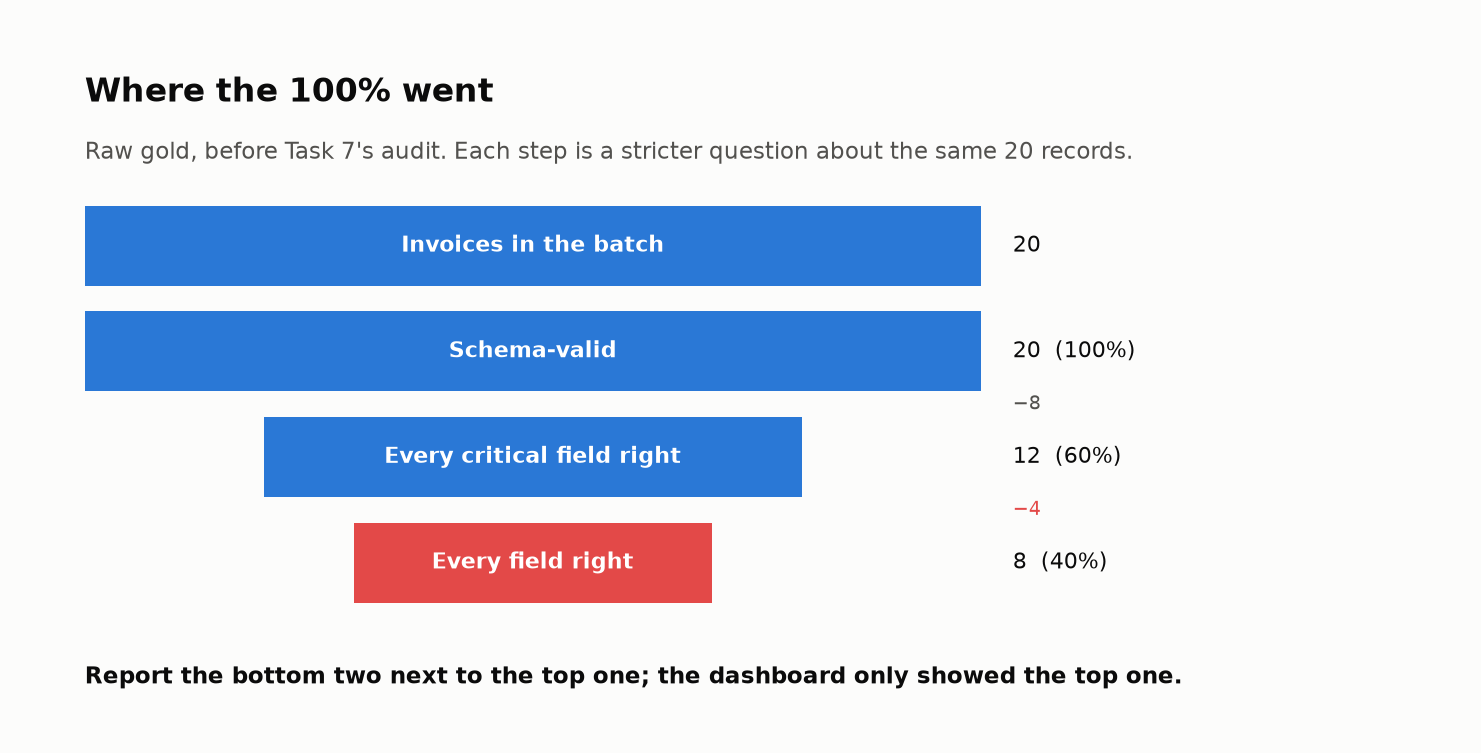
<sub>🖼️ *Four questions about the same 20 records; only the first one was on the dashboard.*</sub>

🎛️ **Experiment:** drag `P_FIELD` to **0.99**: 13% of invoices are still wrong. Set `K_FIELDS` to **50**: what `P_FIELD` keeps 95% whole?

<!-- img: errors-compound.png -->
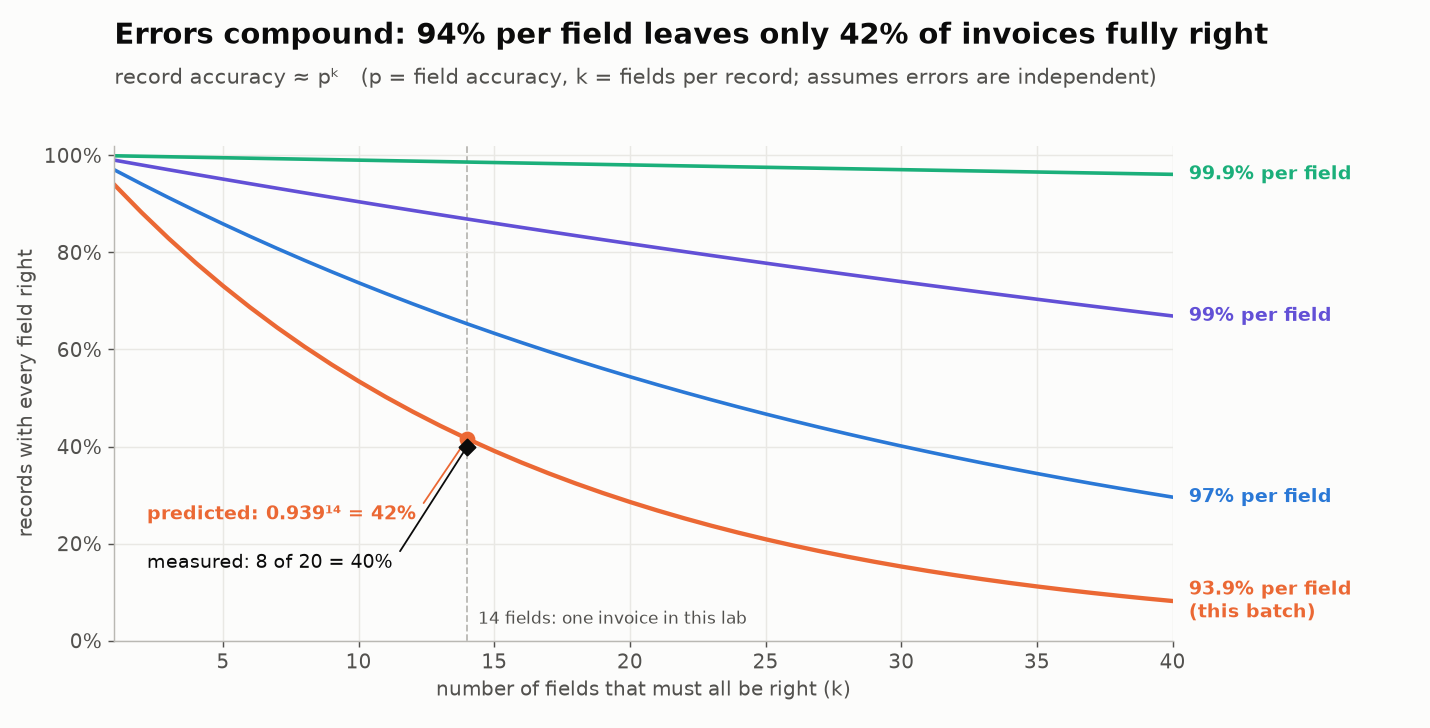

<sub>🖼️ *Record accuracy ≈ pᵏ. Each extra field is another chance to be wrong.*</sub>

In [ ]:
# 🎛️ Record accuracy ≈ p^k. The defaults are this batch: 93.93% per field, 14 fields.
P_FIELD = 0.9393  # @param {type:"slider", min:0.9, max:0.9999, step:0.0001}
K_FIELDS = 14  # @param {type:"slider", min:1, max:60, step:1}

print(f"{P_FIELD:.2%} per field × {K_FIELDS} fields → {P_FIELD ** K_FIELDS:.0%} of records fully right")

<details><summary>📋 <b>Checkpoint</b>: compare with the expected output</summary>

**Checkpoint ✅** Bars: **100%** · **94%** · **93%** · **60%** · **40%**. 🔎 typo **0.929**, legitimate **0.923**.
</details>

🗣️ **Say it to a colleague:** "Field accuracy is what the model does. Record accuracy is what the customer gets. Report both, gate on the second."

In [ ]:
# @title ❓ Quick check: the OCR typo TechParts lnc. scores 0.929 against the gold; the legitimate Bayside Freight Partners vs … LLC scores 0.923. Which fuzzy threshold accepts the second and rejects the first?
answer = "— pick one —"  # @param ["— pick one —", "A) 0.925", "B) None: the typo scores higher, so normalise instead", "C) 0.90, plus a manual review queue", "D) 0.95"]
quiz('A fuzzy-match threshold?', answer, correct="B",
     why="Similarity counts characters, not meaning: one wrong letter costs less than a dropped legal suffix. Normalising (casefold, strip punctuation, drop LLC) accepts the suffix and rejects the typo.",
     wrong={"A": '0.925 rejects Bayside (0.923) and accepts the typo (0.929): exactly backwards.',
          "C": '0.90 accepts both, including a typo in who gets paid.',
          "D": '0.95 rejects both, including the correct LLC record.'})

<table><tr><td>

🔑 **Key takeaway**<br>
<font size="5" color="#2a78d6"><b>Report record accuracy next to field accuracy, and gate on records.</b></font>

</td></tr></table>

---

## Task 6: Null handling: abstain, hallucinate or omit? 🕳️

<big><b>An invented due date pays early; an invented PO number passes a three-way match.</b></big>

> 🎯 **Goal:** sort 60 nullable slots into abstentions, hallucinations and omissions; trace each invention.<br>
> ❓ **The question:** what does a model do when the page prints nothing?<br>
> 👀 **Watch for:** where each invented value came from.

<!-- img: null-confusion.png -->
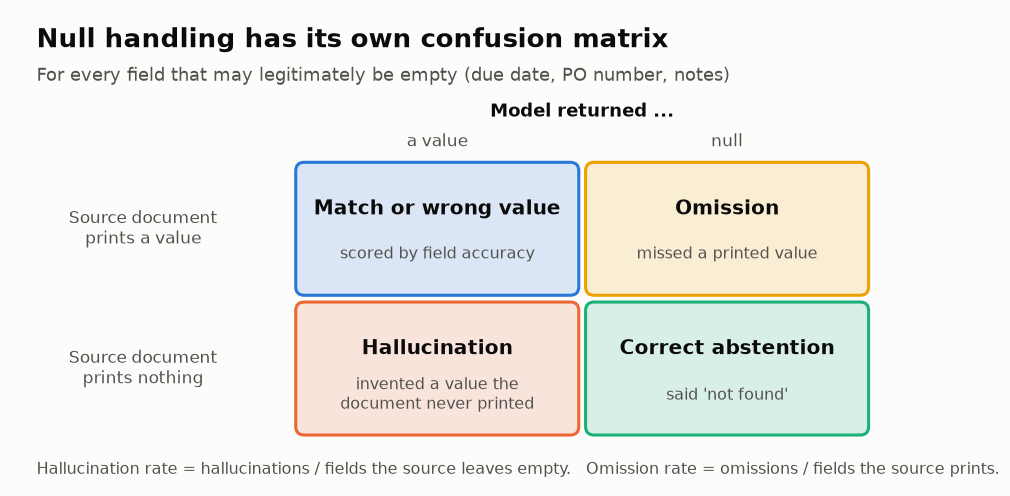

<sub>🖼️ *Null handling has its own confusion matrix.*</sub>

> 📘 **Concept · Hallucination vs omission**
>
> **What it is:** on a field the source leaves empty, a returned value is a *hallucination*; on a field the source prints, a returned `null` is an *omission*.
>
> **What it can't tell you:** a single accuracy number: it lets a model trade one for the other unnoticed, so report the two rates separately.
>
> **Anchor:** a due date computed from 'Due on receipt' and a PO number copied from the neighbouring invoice: both well-typed, both invented.

In [ ]:
# @title 🔮 Predict: of the fields the source leaves empty, what share did the model fill in anyway?
hallucination_will_be = "— pick one —"  # @param ["— pick one —", "A) 0%: strict mode prevents it", "B) about 2%", "C) about 10%", "D) 25% or more"]
print("🔮 Locked in. Graded after the reveal.")

▶️ **Run:** outcome rules, and `provenance()`: where did an invented value come from?

In [ ]:
NULLABLE = ["due_date", "po_number", "notes"]


def null_outcome(pred, gold):
    if gold is None:
        return "✅ correct abstention" if pred is None else "🚨 hallucinated value"
    return "🕳️ omission" if pred is None else "value vs value"


def provenance(iid, value):
    """Where could an invented value have come from?"""
    if value in SOURCES[iid]:
        return "printed in THIS invoice's own source 🤔"
    elsewhere = [j for j in SOURCES if j != iid and value in SOURCES[j]]
    if elsewhere:
        return f"copied from {elsewhere[0]}'s document"
    try:
        days = (date.fromisoformat(value) - date.fromisoformat(outputs[iid]["invoice_date"])).days
        return f"computed: invoice_date + {days} days (terms say {outputs[iid]['payment_terms']!r})"
    except ValueError:
        return "found nowhere"


def null_report(outs, gold):
    rows = [{"invoice": iid, "field": f, "pred": outs[iid][f], "gold": gold[iid][f],
             "outcome": null_outcome(outs[iid][f], gold[iid][f])} for iid in gold for f in NULLABLE]
    return pd.DataFrame(rows)

▶️ **Run:** every problem slot → read the last column.

In [ ]:
nulls = null_report(outputs, GOLD)
counts = nulls["outcome"].value_counts()
gold_empty = int((nulls["gold"].isna()).sum())
gold_present = len(nulls) - gold_empty
n_hall, n_omit = int(counts.get("🚨 hallucinated value", 0)), int(counts.get("🕳️ omission", 0))
hall_rate, omit_rate = n_hall / gold_empty, n_omit / gold_present

problems = nulls[nulls["outcome"].isin(["🚨 hallucinated value", "🕳️ omission"])].copy()
problems["where the value came from"] = [provenance(r.invoice, r.pred) if isinstance(r.pred, str)
                                         else "(model returned null)" for r in problems.itertuples()]
display(problems[["invoice", "field", "pred", "gold", "outcome", "where the value came from"]]
        .astype(object).fillna("null").reset_index(drop=True))

# A schema in which "not printed" is NOT representable (the v1 many teams start with)
schema_v1 = deepcopy(invoice_schema)
for f in ("due_date", "po_number"):
    schema_v1["properties"][f]["type"] = "string"
v1 = jsonschema.Draft202012Validator(schema_v1)
unrepresentable = [iid for iid, g in GOLD.items() if not v1.is_valid(g)]

✋ **Your turn:** turn the table into a rate.

In [ ]:
# @title 🧰 Reference answer for the exercise below (hidden · spoiler)
_ref_hall_rate = n_hall / gold_empty

In [ ]:
# ✋ Your turn: the table shows 3 hallucinated values. Of the 60 nullable slots,
#    the source leaves 25 empty (gold_empty) and prints 35 (gold_present).
my_hall_rate = ...   # ✏️ the hallucination rate: n_hall over the right denominator

check("Hallucination rate", my_hall_rate, _ref_hall_rate, tol=1e-3,
      hint="Only a field the source leaves empty can be hallucinated, so only those belong in the denominator.",
      success=f"{n_hall}/{gold_empty} = {_ref_hall_rate:.0%}. Over all {len(nulls)} slots it would read {n_hall / len(nulls):.0%}: the wrong denominator halves the problem.")

▶️ **Run** (code hidden): tiles and two cards → the second shows what a non-nullable schema does to *right* answers.

In [ ]:
# @title 🧰 Tiles + cards: null-handling results (hidden · 26 lines)
tiles([
    ("Empty fields in the source", gold_empty, f"of {len(nulls)} nullable slots", None),
    ("Correct abstentions", int(counts.get("✅ correct abstention", 0)), "said null when nothing was printed", "good"),
    ("Hallucination rate", f"{hall_rate:.0%}", f"{n_hall}/{gold_empty} empty fields filled in", "critical" if n_hall else "good"),
    ("Omission rate", f"{omit_rate:.0%}", f"{n_omit}/{gold_present} printed values missed", "warning" if n_omit else "good"),
])
insight(
    f"The model invented {n_hall} values for {gold_empty} empty fields ({hall_rate:.0%}), and each invention looks real",
    "One due date was *computed* from the invoice date although the terms say 'Due on receipt'; one PO number "
    "was *copied from another invoice in the batch*. Both are well-typed and plausible, and pass every schema "
    "check. The third \"hallucination\" is printed in its own source document: remember it for Task 7.\n"
    "**Rule of thumb:** report hallucination rate (on empty fields) and omission rate (on printed fields) as two "
    "numbers; one accuracy figure lets a model trade one for the other unnoticed.",
    kind="insight",
)
insight(
    f"With a non-nullable schema, the correct answer is unrepresentable for {len(unrepresentable)} of {len(GOLD)} invoices",
    f"Validate the *gold labels* against a v1 schema where `due_date` and `po_number` are plain strings: "
    f"{len(unrepresentable)} correct records fail ({', '.join(i[-4:] for i in unrepresentable)}). Constrained "
    "decoding only emits what the grammar allows, so for those invoices a fabricated value is the *only* legal "
    "output. That is a mechanism, not a measured effect: no study has put a number on it yet, so test your own "
    "schema.\n"
    "**Rule of thumb:** every field that can be absent must be nullable (or carry an explicit `\"NOT_FOUND\"` "
    "value), and absent values belong in your eval set.",
    kind="warning",
)

▶️ **Run:** grades your prediction.

In [ ]:
_p_hall = "A" if hall_rate < 0.01 else "B" if hall_rate < 0.05 else "C" if hall_rate < 0.2 else "D"
quiz("Your prediction: hallucination rate", hallucination_will_be, correct=_p_hall,
     why=f"{n_hall} of {gold_empty} ({hall_rate:.0%}): a due date computed from the terms, a PO number copied from another invoice, and one value printed on its own page (Task 7).")

🔍 **What just happened:** a computed due date is an **instruction** problem; a copied PO number is **context contamination**.

🎲 ▶️ **Run:** a toy decoder for INV-2026-0114's `due_date` (nothing printed): mask `null`, **renormalise** the rest, pick the top.

In [ ]:
TOY_PREFS = {"null": 0.62, "2026-04-18": 0.24, "2026-03-19": 0.10, "2026-05-03": 0.04}  # illustrative


def masked(prefs, allowed):
    kept = {tok: p for tok, p in prefs.items() if allowed(tok)}
    return {tok: p / sum(kept.values()) for tok, p in kept.items()}


views = {"nullable  (type: [string, null])": masked(TOY_PREFS, lambda t: True),
         "non-nullable  (type: string)": masked(TOY_PREFS, lambda t: t != "null")}
fig, axes = plt.subplots(1, 2, figsize=(10, 2.8), sharey=True)
for ax, (name, dist) in zip(axes, views.items()):
    pick = max(dist, key=dist.get)
    toks = list(TOY_PREFS)
    ax.barh(toks[::-1], [dist.get(t, 0) for t in toks[::-1]],
            color=[(PALETTE[2] if t == "null" else PALETTE[1]) if t == pick else "#c9c8c3" for t in toks[::-1]])
    for t in toks:
        ax.text(dist.get(t, 0) + 0.02, toks[::-1].index(t), "masked" if t not in dist else f"{dist[t]:.2f}",
                va="center", fontsize=10, color="#52514e")
    ax.set_xlim(0, 1.05); ax.set_title(name, fontsize=11, loc="left"); ax.grid(axis="y", visible=False)
    ax.set_xlabel(f"emits {pick!r}")
fig.suptitle("Remove null from the grammar and the same preferences must invent a due date", x=0.01, ha="left",
             fontweight="bold", fontsize=13)
plt.tight_layout()
plt.show()
forced = views["non-nullable  (type: string)"]
print(f"Nullable: emits null (p = {TOY_PREFS['null']:.2f}).\nNon-nullable: null is masked, so it emits "
      f"{max(forced, key=forced.get)!r} (p = {max(forced.values()):.2f} after renormalising), a Net 30 date by habit.")


<details><summary>📋 <b>Checkpoint</b>: compare with the expected output</summary>

**Checkpoint ✅** 0103 due date *computed*, 0109 PO *omitted*, 0110 PO *copied from 0109*, 0119 *printed in its own source* 🤔. Tiles **25** · **22** · **12%** · **3%**.
</details>

🗣️ **Say it to a colleague:** "Absence is a value. If 'not found' isn't representable, the model's only legal output is an invention."

In [ ]:
# @title ❓ Quick check: a v1 schema makes due_date a plain string (not nullable). The invoice says Due on receipt. What does strict mode return?
answer = "— pick one —"  # @param ["— pick one —", "A) A date: null is masked, so the most likely legal value wins", "B) null, because the prompt says never guess", "C) A refusal", "D) An error the schema check catches"]
quiz('Non-nullable due date', answer, correct="A",
     why="Constrained decoding only emits what the grammar allows. With null masked, its probability goes to dates: the toy decoder picked a Net 30 date. The result is valid and wrong.",
     wrong={"B": "The prompt can't override the grammar: null isn't a legal token any more.",
          "C": 'Refusals are for unsafe requests, not missing fields.',
          "D": 'A date is a valid string, so every schema check passes.'})

<table><tr><td>

🔑 **Key takeaway**<br>
<font size="5" color="#2a78d6"><b>Make "not found" representable, and report hallucination and omission as two rates.</b></font>

</td></tr></table>

---

## Task 7: Audit the gold: is it the model, or the label? 🏷️

<big><b>Every metric so far trusted the answer key. Should it have?</b></big>

> 🎯 **Goal:** classify every model-vs-gold disagreement as a model error, a **label error** or ambiguous, then re-score.<br>
> ❓ **The question:** how many "model errors" are the answer key's fault?<br>
> 👀 **Watch for:** a date that reads correctly two ways.

The **source document** is the third witness. `supported()` finds a value *as printed*:

| Model value on the page? | Gold value on the page? | Verdict |
|---|---|---|
| no | yes | 🤖 **model error** |
| yes | no | 🏷️ **label error**: fix the gold |
| both, or neither | | 🧑‍⚖️ **ambiguous**: send to a human |

In [ ]:
# @title 🔮 Predict: of all the model-vs-gold disagreements, how many are the answer key's fault?
label_errors_will_be = "— pick one —"  # @param ["— pick one —", "A) None: the gold is the truth", "B) 1–2", "C) 3–5", "D) more than 5"]
print("🔮 Locked in. Graded after the reveal.")

▶️ **Run** (code hidden): regexes for values as printed.

In [ ]:
# @title 🧰 Regexes for money and line items as printed on the page (hidden · 14 lines · expand if curious)
CURRENCY_MARKERS = {"USD": ["USD", "US$"], "CAD": ["CAD", "C$"], "GBP": ["GBP", "£"], "EUR": ["EUR", "€"]}
FIELD_LABELS = {"due_date": "Due date:", "po_number": "PO number:", "notes": "Notes:"}


def _printed(number):
    """Regex for a money value as printed on the invoice (e.g. 1,846.80), not part of a longer number."""
    return r"(?<![\d.,])" + re.escape(f"{number:,.2f}") + r"(?!\d)"


def _item_printed(li):
    """Regex for one line item as printed: '<qty> x <symbol><unit price>  <symbol><line total>'."""
    sym = r"[^\d\s]*"   # an optional currency symbol such as $, C$ or £
    return (r"(?<![\d.])" + re.escape(f"{li['quantity']:g}") + r" x\s+" + sym + re.escape(f"{li['unit_price']:,.2f}")
            + r"\s+" + sym + re.escape(f"{li['line_total']:,.2f}") + r"(?!\d)")

▶️ **Run:** `supported()` and `classify()`: the table in code.

In [ ]:
def supported(field, value, text):
    """Does the source document literally support this value?"""
    if value is None:
        return field in FIELD_LABELS and FIELD_LABELS[field] not in text
    if field in MONEY:
        return re.search(_printed(value), text) is not None
    if field == "tax_rate":
        return f"({value * 100:g}%)" in text
    if field in ("invoice_date", "due_date"):
        d = date.fromisoformat(value)
        return any(form in text for form in (value, d.strftime("%m/%d/%Y"), d.strftime("%d/%m/%Y")))
    if field == "currency":
        return any(marker in text for marker in CURRENCY_MARKERS.get(value, [value]))
    if field == "line_items":
        return all(re.search(_item_printed(li), text) for li in value)
    return norm_text(value) in norm_text(text)


def classify(pred_ok, gold_ok):
    if pred_ok and not gold_ok:
        return "🏷️ label error"
    if gold_ok and not pred_ok:
        return "🤖 model error"
    return "🧑‍⚖️ ambiguous → human"


print("🔎 Audit tools ready: supported(), classify()")


✋ **Your turn:** audit five disagreements before the code audits all 17. ▶️ **Run** the case cards (code hidden), then pick verdicts in the next cell.

In [ ]:
# @title 🕵️ Five disagreements to audit: the case cards (hidden · 72 lines)
AUDIT_GAME = [  # (invoice, field, the source lines worth reading)
    ("INV-2026-0107", "currency", ["Maple Leaf", "Toronto", "Currency:", "TOTAL:"]),
    ("INV-2026-0118", "total_amount", ["Subtotal:", "Tax (", "TOTAL:"]),
    ("INV-2026-0106", "invoice_date", ["Brightline", "London", "Invoice date:", "Due date:"]),
    ("INV-2026-0110", "po_number", ["Quick Print", "Portland", "PO number:", "Terms:"]),
    ("INV-2026-0119", "due_date", ["Fernwood", "Invoice date:", "Due date:", "Terms:"]),
]
VERDICTS = {"model error": "🤖 model error", "label error": "🏷️ label error", "ambiguous → human": "🧑‍⚖️ ambiguous → human"}
WHY = {
    "INV-2026-0107": "Toronto address, C$ amounts, and \"USD\" appears nowhere on the page. Model error: an identity "
                     "error no arithmetic rule can see.",
    "INV-2026-0118": "TOTAL on the page is 1,846.80, the model's value; the labeller transposed two digits. Label error.",
    "INV-2026-0106": "04/03/2026 fits both readings. The London address says day-first, so a human sides with the gold, "
                     "but the text alone can't prove it: route it to a person or a locale rule.",
    "INV-2026-0110": "No PO line on this page; PO-48213 is printed on INV-2026-0109. Model error: a value copied from a "
                     "neighbouring document.",
    "INV-2026-0119": "The page prints \"Due date: 2026-05-10\", exactly the model's value; the labeller missed it. "
                     "Label error.",
}


def _excerpt(iid, keys):
    lines = SOURCES[iid].splitlines()
    shown = [ln for ln in lines if any(k in ln for k in keys)]
    absent = [k for k in keys if k.endswith(":") and not any(k in ln for ln in lines)]
    return shown + [f"   (no '{k}' line on this invoice)" for k in absent]


def _fmt(v):
    return "null" if v is None else f"{v:,.2f}" if isinstance(v, float) else str(v)


def score_audit(verdicts):
    rows = []
    for k, (iid, field, _) in enumerate(AUDIT_GAME, 1):
        pred, gold, text = outputs[iid][field], GOLD[iid][field], SOURCES[iid]
        truth = classify(supported(field, pred, text), supported(field, gold, text))
        mine = verdicts[iid]
        ok = mine == truth or (truth.startswith("🧑") and mine.startswith("🤖"))  # 0106: locale knowledge counts
        rows.append((k, iid, field, mine, truth, ok))
    return rows


def show_audit_score(verdicts):
    rows = score_audit(verdicts)
    right = sum(r[5] for r in rows)
    body = "".join(
        f"<tr style='border-top:1px solid #e4e3df;vertical-align:top'><td>{'✅' if ok else '❌'}</td>"
        f"<td style='white-space:nowrap;padding-right:10px'>{k}. {iid[-4:]} <code>{f}</code></td>"
        f"<td style='white-space:nowrap;padding-right:10px'>{mine}</td>"
        f"<td style='white-space:nowrap;padding-right:10px'><b>{truth}</b></td><td style='color:#52514e'>{_html.escape(WHY[iid])}</td></tr>"
        for k, iid, f, mine, truth, ok in rows)
    _show(f"<div style='font-family:system-ui,-apple-system,sans-serif;max-width:900px;color:#0b0b0b'>"
          f"<div style='font-size:18px;font-weight:700;margin:6px 0'>🕵️ Your audit: {right} of {len(rows)} right</div>"
          f"<table style='border-collapse:collapse;font-size:13px;line-height:1.4'><tr style='text-align:left'><th></th>"
          f"<th>case</th><th>you</th><th>the audit</th><th>why</th></tr>{body}</table></div>")
    return right


cards = []
for k, (iid, field, keys) in enumerate(AUDIT_GAME, 1):
    page = _html.escape("\n".join(_excerpt(iid, keys)))
    cards.append(
        f"<div style='flex:1 1 400px;border:1px solid #e4e3df;border-top:4px solid #6250d6;border-radius:8px;"
        f"padding:10px 14px;background:#fcfcfb'>"
        f"<div style='font-weight:700'>Case {k} · {iid} · <code>{field}</code></div>"
        f"<div style='margin:8px 0;font-size:13px'>"
        f"<span style='background:#f1effc;padding:2px 8px;border-radius:10px'>🤖 model: <b>{_fmt(outputs[iid][field])}</b></span> "
        f"<span style='background:#fdf6e6;padding:2px 8px;border-radius:10px'>🏷️ gold: <b>{_fmt(GOLD[iid][field])}</b></span></div>"
        f"<pre style='background:#f3f2ef;padding:8px;border-radius:6px;font-size:12px;margin:0;white-space:pre-wrap'>{page}</pre></div>")
_show("<div style='display:flex;flex-wrap:wrap;gap:10px;max-width:900px;font-family:system-ui,-apple-system,sans-serif;"
      "color:#0b0b0b'>" + "".join(cards) + "</div>")

In [ ]:
# @title ✋ Your turn: you're the auditor. Pick a verdict for each case, then run this cell.
# ✋ Your turn: you're the auditor. Read each case card above, then pick a verdict per case.
case_1 = "— pick one —"  # @param ["— pick one —", "model error", "label error", "ambiguous → human"]
case_2 = "— pick one —"  # @param ["— pick one —", "model error", "label error", "ambiguous → human"]
case_3 = "— pick one —"  # @param ["— pick one —", "model error", "label error", "ambiguous → human"]
case_4 = "— pick one —"  # @param ["— pick one —", "model error", "label error", "ambiguous → human"]
case_5 = "— pick one —"  # @param ["— pick one —", "model error", "label error", "ambiguous → human"]

picks = [case_1, case_2, case_3, case_4, case_5]
if any(p not in VERDICTS for p in picks):
    check("You're the auditor", ..., ok=False)
else:
    audit_score = show_audit_score({iid: VERDICTS[p] for (iid, _, _), p in zip(AUDIT_GAME, picks)})
    check("You're the auditor", audit_score, len(AUDIT_GAME),
          hint="For each case ask: is the model's value printed on the page? Is the gold's? Read the 'why' column.",
          success="5 of 5. Two of the five 'model errors' were the labeller's, and one can't be settled from the text alone.")

▶️ **Run:** audits all 17, then re-scores against the corrected `GOLD_FIXED`.

In [ ]:
audit = []
for row in scored[~scored["correct"]].itertuples():
    pred, gold = outputs[row.invoice][row.field], GOLD[row.invoice][row.field]
    p_ok, g_ok = supported(row.field, pred, SOURCES[row.invoice]), supported(row.field, gold, SOURCES[row.invoice])
    short = lambda v: (f"[{len(v)} items]" if isinstance(v, list) else v)
    audit.append({"invoice": row.invoice, "field": row.field, "model": short(pred), "gold": short(gold),
                  "model in source": p_ok, "gold in source": g_ok, "verdict": classify(p_ok, g_ok)})
audit = pd.DataFrame(audit)
display(audit)

# Correct the answer key where the source clearly sides with the model.
GOLD_FIXED = deepcopy(GOLD)
for r in audit[audit["verdict"] == "🏷️ label error"].itertuples():
    GOLD_FIXED[r.invoice][r.field] = deepcopy(outputs[r.invoice][r.field])

scored_fixed = score_batch(outputs, GOLD_FIXED)
S2 = summarize(scored_fixed)
nulls_fixed = null_report(outputs, GOLD_FIXED)
gold_empty2 = int(nulls_fixed["gold"].isna().sum())
n_hall2 = int((nulls_fixed["outcome"] == "🚨 hallucinated value").sum())
hall_rate2 = n_hall2 / gold_empty2
v = audit["verdict"].value_counts()
n_label, n_model, n_amb = (int(v.get(k, 0)) for k in ("🏷️ label error", "🤖 model error", "🧑‍⚖️ ambiguous → human"))

▶️ **Run** (code hidden): before → after tiles and a 🤯 card.

In [ ]:
# @title 🧰 Tiles + card: what the gold fix changes (hidden · 23 lines)
tiles([
    ("Disagreements audited", len(audit), "model ≠ gold", None),
    ("🤖 Model errors", n_model, "source backs the gold", "serious"),
    ("🏷️ Label errors", n_label, "source backs the model", "warning" if n_label else "good"),
    ("🧑‍⚖️ Ambiguous", n_amb, "text alone can't decide", "warning" if n_amb else "good"),
])
tiles([
    ("Record accuracy", f"{S['full_records'] / n:.0%} → {S2['full_records'] / n:.0%}", "raw gold → corrected gold", None),
    ("Critical-record accuracy", f"{S['crit_records'] / n:.0%} → {S2['crit_records'] / n:.0%}", "raw → corrected", None),
    ("Hallucination rate", f"{hall_rate:.0%} → {hall_rate2:.0%}", f"{n_hall2}/{gold_empty2} after the fix", None),
])
insight(
    f"{n_label} of {len(audit)} \"model errors\" were the answer key's fault",
    f"INV-2026-0118's gold total has two transposed digits; INV-2026-0119's labeller missed a printed due date "
    f"(Task 6's third \"hallucination\"). Fixing both moves record accuracy from {S['full_records'] / n:.0%} to "
    f"{S2['full_records'] / n:.0%} and the hallucination rate from {hall_rate:.0%} to {hall_rate2:.0%}. The "
    f"{n_amb} ambiguous rows are INV-2026-0106's dates: `04/03/2026` is 4 March in London and April 3 in Austin, the "
    "text supports both, and only the vendor's UK address settles it, so a human or a locale rule must.\n"
    "**Rule of thumb:** check the source before blaming the model, budget for re-labelling, and treat \"model beats "
    "gold\" as a finding. Cleanlab found erroneous or inconsistent ground truth in **every** public "
    "structured-output benchmark it examined.",
    kind="surprise",
)

▶️ **Run:** grades your prediction.

In [ ]:
_p_label = "A" if n_label == 0 else "B" if n_label <= 2 else "C" if n_label <= 5 else "D"
quiz("Your prediction: label errors", label_errors_will_be, correct=_p_label,
     why=f"{n_label} of {len(audit)}: 0118's transposed total and 0119's missed due date. Fixing them moved record accuracy from {S['full_records'] / n:.0%} to {S2['full_records'] / n:.0%}.")

> 📘 **Concept · Label error**
>
> **What it is:** a gold value that the source document itself contradicts; the model is right and the answer key is wrong.
>
> **What it can't tell you:** it can't be found by comparing model and gold; only the source can arbitrate, so every disagreement needs a third witness.
>
> **Anchor:** INV-2026-0118's gold total has two transposed digits; the model read the page correctly and was scored as an error.

<!-- img: comic-gold-audit.png -->
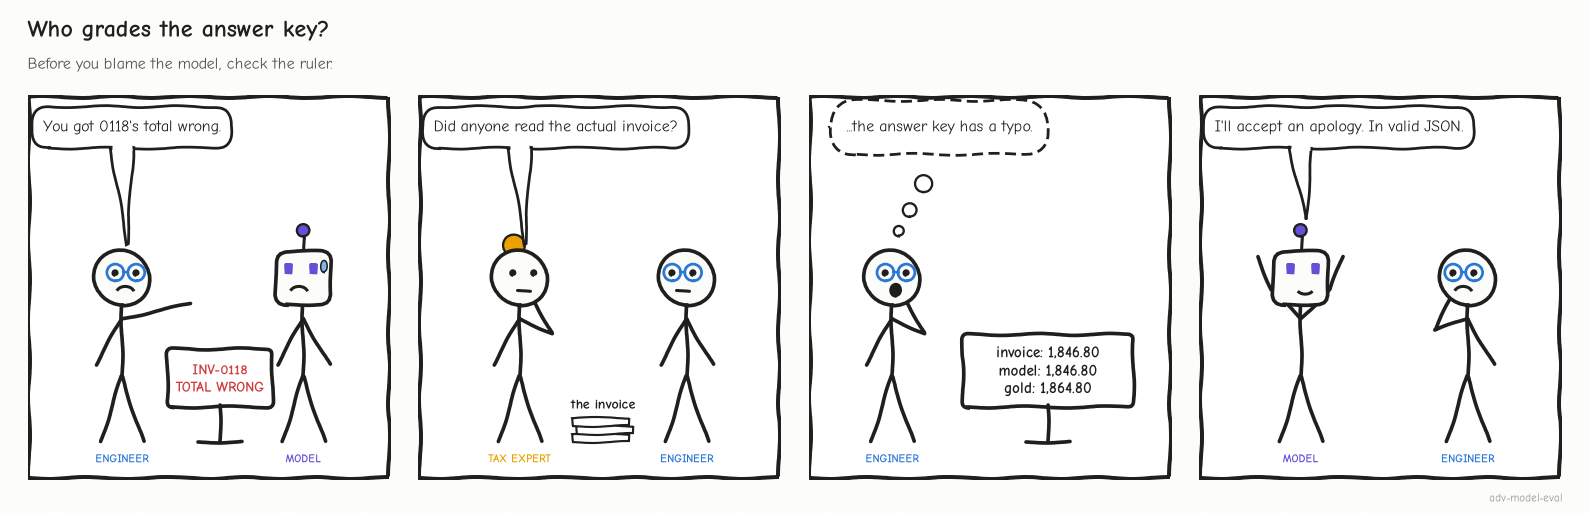

<sub>🖼️ *Who grades the answer key? Check the source before you blame the model.*</sub>

🔍 **What just happened:** a wrong gold label hides real errors and invents fake ones. <mark>From here on, every metric uses `GOLD_FIXED`.</mark>

<!-- img: three-verdicts.png -->
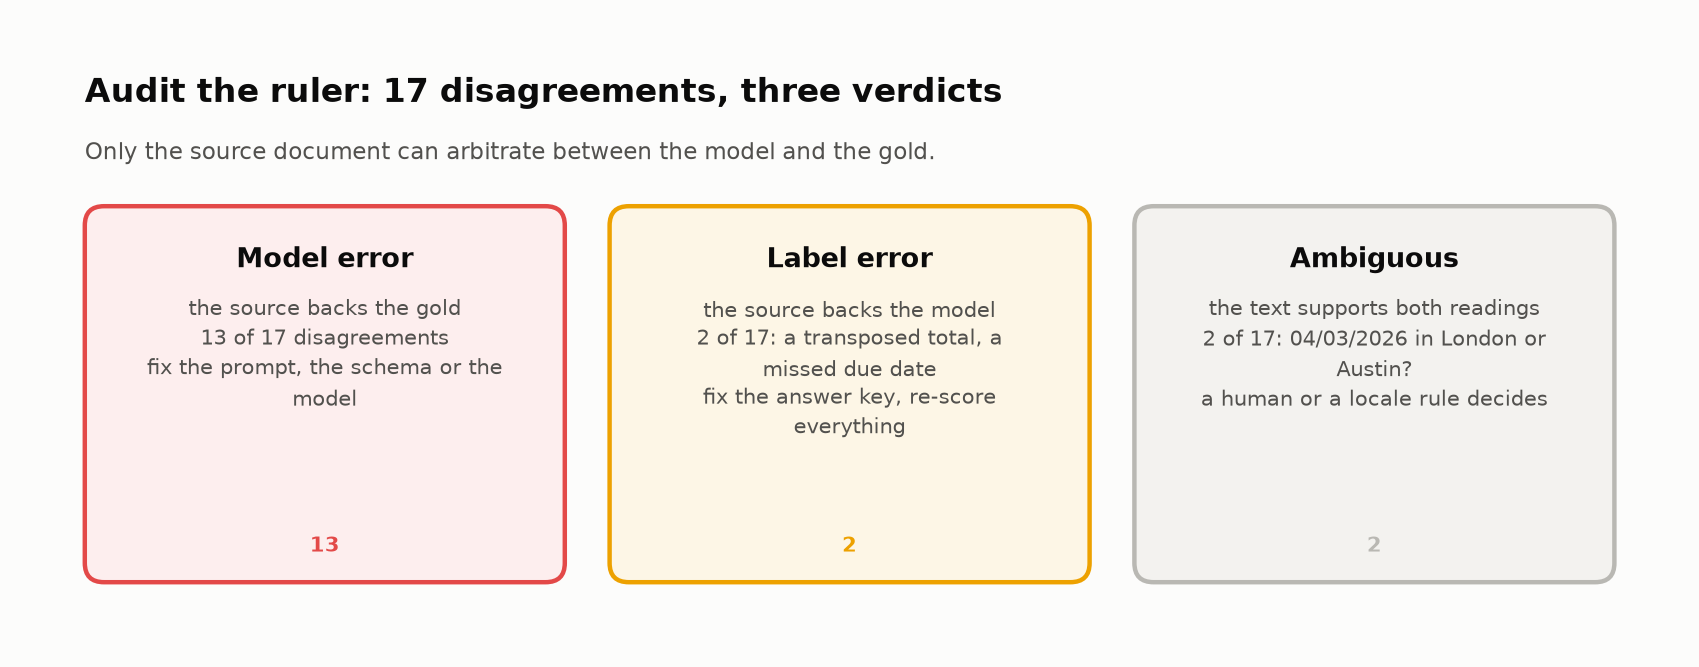
<sub>🖼️ *The source document is the third witness in every disagreement.*</sub>

<details><summary>📋 <b>Checkpoint</b>: compare with the expected output</summary>

**Checkpoint ✅** **13** 🤖 · **2** 🏷️ (0118, 0119) · **2** 🧑‍⚖️ (0106). Record accuracy **40% → 50%**.
</details>

🗣️ **Say it to a colleague:** "Audit the ruler before the measurement. When the model beats the gold, fix the gold and re-score everything."

In [ ]:
# @title ❓ Quick check: model and gold disagree on a value. Why can't comparing the two tell you who is wrong?
answer = "— pick one —"  # @param ["— pick one —", "A) It can: the model is wrong unless proven otherwise", "B) It can, with fuzzy matching", "C) Label errors are too rare to matter", "D) They are two claims about a third thing: only the source document can arbitrate"]
quiz('Who arbitrates?', answer, correct="D",
     why="A disagreement only says they differ. The source decided 15 of 17 here, and twice it sided with the model.",
     wrong={"A": 'That default scored 3 of 5 in the auditor game.',
          "B": "Similarity can't tell which value is printed on the page.",
          "C": 'Two of them moved record accuracy and the hallucination rate.'})

<table><tr><td>

🔑 **Key takeaway**<br>
<font size="5" color="#2a78d6"><b>Check the source before you blame the model: audit the answer key.</b></font>

</td></tr></table>

---

## 🔑 Part 1 in three lines

1. **Schema-valid ≠ correct:** 100% valid, 8 of 20 invoices fully right.
2. **Absence is a value:** make `null` legal; count hallucinations on empty fields only.
3. **Audit the gold:** the source document decides who is wrong.

▶️ **Run:** your score on Part 1's exercises and checks, and what to revisit.

In [ ]:
scoreboard()

<center><font size="5"><b>➡️ Continue in Part 2: what can you catch with no labels, and do you ship?</b></font></center>

<center>

[![Open Part 2 In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/varoonsahgal/adv-model-eval-student/blob/main/labs/03-structured-outputs-part-2-lab.ipynb)

</center>

Part 2 rebuilds Part 1 in one hidden cell.